## Pricing using Belgian MTPL dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Poisson, NegativeBinomial, Gamma, InverseGaussian, Tweedie
from statsmodels.genmod.families.links import Log
import statsmodels.api as sm
from scipy import stats
import json

In [2]:


mtpl = pd.read_csv(".tmp/beMTPL97.csv")
print(mtpl.shape)
mtpl.head()

(163212, 18)


,id,expo,claim,nclaims,amount,average,coverage,ageph,sex,bm,power,agec,fuel,use,fleet,postcode,long,lat
0,1,1.000000,1,1,1618.001036,1618.001036,TPL,50,male,5,77,12,gasoline,private,0,1000,4.355223,50.845386
1,2,1.000000,0,0,0.000000,NaN,TPL+,64,female,5,66,3,gasoline,private,0,1000,4.355223,50.845386
2,3,1.000000,0,0,0.000000,NaN,TPL,60,male,0,70,10,diesel,private,0,1000,4.355223,50.845386
3,4,1.000000,0,0,0.000000,NaN,TPL,77,male,0,57,15,gasoline,private,0,1000,4.355223,50.845386
4,5,0.046575,1,1,155.974606,155.974606,TPL,28,female,9,70,7,gasoline,private,0,1000,4.355223,50.845386


## Data dictionary — `beMTPL97`

Belgian motor third-party liability portfolio: 163,212 unique policyholders, each observed
over an exposure-to-risk period. Five categorical, four continuous, and two spatial risk
factors. Source: [CASdatasets — beMTPL97](https://dutangc.github.io/CASdatasets/reference/beMTPL97.html)

| Variable | Type | Description |
|---|---|---|
| `id` | numeric | Policy number |
| `expo` | numeric | Exposure — fraction of the year the policyholder was at risk |
| `claim` | factor | Claim occurrence indicator (0 = no claim, 1 = at least one claim) |
| `nclaims` | numeric | Number of claims filed |
| `amount` | numeric | Aggregate claim amount (EUR) |
| `average` | numeric | Average claim amount (EUR); `NaN` when `nclaims == 0` |
| `coverage` | factor | Coverage level: `TPL` (liability only), `TPL+` (+ limited material damage), `TPL++` (+ comprehensive material damage) |
| `ageph` | numeric | Policyholder age |
| `sex` | factor | Policyholder gender: `female`, `male` |
| `bm` | integer | Level on the former compulsory Belgian bonus-malus scale (0–22; higher = worse claims history) |
| `power` | numeric | Vehicle horsepower (kW) |
| `agec` | numeric | Vehicle age (years) |
| `fuel` | factor | Fuel type: `gasoline`, `diesel` |
| `use` | factor | Vehicle use: `private`, `work` |
| `fleet` | integer | Part of a fleet: 1 or 0 |
| `postcode` | integer | Policyholder's postal code |
| `long` | numeric | Longitude of the centre of the policyholder's municipality |
| `lat` | numeric | Latitude of the centre of the policyholder's municipality |

**Note:** `average` is `NaN` (not missing data) for the ~89% of policies with zero claims —
there's nothing to average.

In [3]:
print("Number of Policies with 0 claims:", mtpl[mtpl['claim'] == 0].shape[0], "({:.2f}%)".format(mtpl[mtpl['claim'] == 0].shape[0] / mtpl.shape[0] * 100))
print("Number of Policies with 1+ claims:", mtpl[mtpl['claim'] == 1].shape[0], "({:.2f}%)".format(mtpl[mtpl['claim'] == 1].shape[0] / mtpl.shape[0] * 100))


Number of Policies with 0 claims: 144936 (88.80%)
Number of Policies with 1+ claims: 18276 (11.20%)


## 1. Data Cleaning & Exploratory Analysis

In [4]:
#check for missing values
print("Missing values in each column:")
print(mtpl.isnull().sum())

Missing values in each column:
id               0
expo             0
claim            0
nclaims          0
amount           0
average     144936
coverage         0
ageph            0
sex              0
bm               0
power            0
agec             0
fuel             0
use              0
fleet            0
postcode         0
long             0
lat              0
dtype: int64


The  data is clean and has no missing values. The dataset contains 144936 policies with 0 claims and 18276 policies with 1 or more claims. The percentage of policies with 0 claims is 88.80% and the percentage of policies with 1 or more claims is 11.20%.

In [5]:
print(f'Exposure range: [{mtpl["expo"].min():.4f}, {mtpl["expo"].max():.4f}]')
print(f'Policies with Exposure > 1: {(mtpl["expo"] > 1).sum()}')
print(f'Policies with Exposure <= 0: {(mtpl["expo"] <= 0).sum()}')
print(f'Policies with very short exposure (< 0.01): {(mtpl["expo"] < 0.01).sum()}')

Exposure range: [0.0027, 1.0000]
Policies with Exposure > 1: 0
Policies with Exposure <= 0: 0
Policies with very short exposure (< 0.01): 369


In [6]:
print(f'Total claim amount range: [{mtpl["amount"].min():.4f}, {mtpl["amount"].max():.4f}]')

Total claim amount range: [0.0000, 140032.4245]


In [7]:
print(f'Bonus Malus range: [{mtpl["bm"].min():.4f}, {mtpl["bm"].max():.4f}]')
print(f'Policies with Bonus Malus = 0 (Best Score): {(mtpl["bm"] == 0).sum()}')
print(f'Policies with Bonus Malus > 15: {(mtpl["bm"] > 15).sum()}')

Bonus Malus range: [0.0000, 22.0000]
Policies with Bonus Malus = 0 (Best Score): 61647
Policies with Bonus Malus > 15: 668


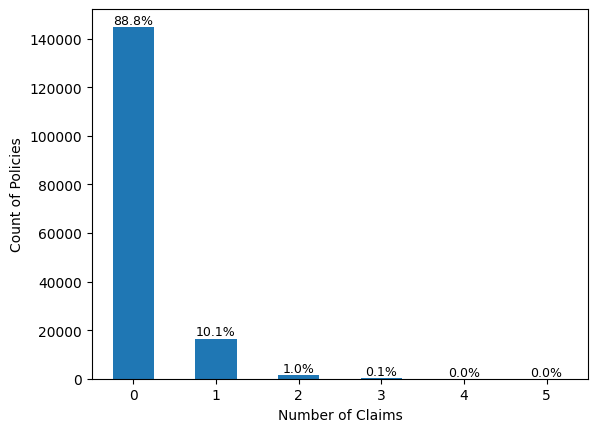

In [8]:
ax = mtpl["nclaims"].value_counts().sort_index().plot(kind = "bar")
total = len(mtpl)
for p in ax.patches:
    pct = p.get_height() / total * 100
    ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha = "center", va = "bottom", fontsize = 9)
plt.xlabel("Number of Claims")
plt.ylabel("Count of Policies")
plt.xticks(rotation = 0)
plt.show()

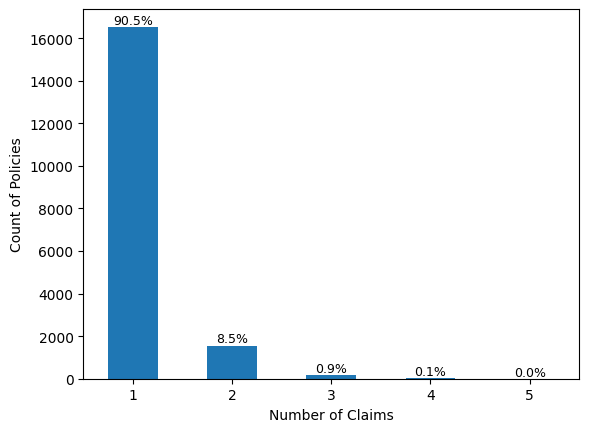

In [9]:
more_than_1 = mtpl[mtpl["claim"] == 1]

ax = more_than_1["nclaims"].value_counts().sort_index().plot(kind = "bar")
total = len(more_than_1)
for p in ax.patches:
    pct = p.get_height() / total * 100
    ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha = "center", va = "bottom", fontsize = 9)
plt.xlabel("Number of Claims")
plt.ylabel("Count of Policies")
plt.xticks(rotation = 0)
plt.show()

In [10]:

# Chart palette (validated categorical/status hues; see dataviz color formula)
COLOR_LINE = '#2a78d6'      # frequency line (categorical slot 1 - blue)
COLOR_BAR = '#e1e0d9'       # exposure bars (recessive, one step off surface)
COLOR_AVG = '#e34948'       # average-frequency reference line (categorical slot 8 - red)
COLOR_INK = '#52514e'       # secondary ink for labels/ticks
COLOR_MUTED = '#898781'     # muted ink for axis titles

def plot_frequency_by_feature(data, feature, ax, is_continuous=False, n_bins=20):
    if is_continuous:
        data['bin'] = pd.cut(data[feature], bins=n_bins)
        group = data.groupby('bin', observed=True).agg(
        total_claims= ('nclaims', 'sum'),
        total_exposure = ('expo', 'sum')
        )
        group['frequency'] = group['total_claims'] / group['total_exposure']
        labels = [f"{interval.left:.0f}-{interval.right:.0f}" for interval in group.index]

    else :
        group = data.groupby(feature, observed=True).agg(
            total_claims=('nclaims', 'sum'),
            total_exposure=('expo', 'sum')
        )
        group['frequency'] = group['total_claims'] / group['total_exposure']
        labels = group.index.astype(str)

    #Exposure bars on another axis, drawn first so the frequency line sits on top

    x = range(len(labels))

    ax2 = ax.twinx()
    ax2.bar(labels, group['total_exposure'].values, color=COLOR_BAR, width=0.6, zorder=1)
    ax2.set_ylabel('Earned Exposure', color=COLOR_MUTED, fontsize=9)
    ax2.tick_params(axis='y', colors=COLOR_MUTED)
    ax2.spines[['top', 'left']].set_visible(False)

    ax.plot(x, group['frequency'], marker='o', linestyle='-', linewidth=2, markersize=8,
            color=COLOR_LINE, markerfacecolor=COLOR_LINE, markeredgecolor='#fcfcfb',
            markeredgewidth=1.5, zorder=3)
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8, color=COLOR_INK)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

    #Average frequency line

    avg_frequency = data['nclaims'].sum() / data['expo'].sum()
    ax.axhline(y=avg_frequency, color=COLOR_AVG, linestyle='--', linewidth=1.5,
               label=f'Average Frequency: {avg_frequency:.4f}', zorder=2)
    ax.legend(fontsize=8, frameon=False, labelcolor=COLOR_INK)
    ax.set_ylabel('Claim Frequency', color=COLOR_INK, fontsize=9)
    ax.set_xlabel(feature, color=COLOR_INK, fontsize=9)
    ax.tick_params(axis='y', colors=COLOR_INK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#c3c2b7')


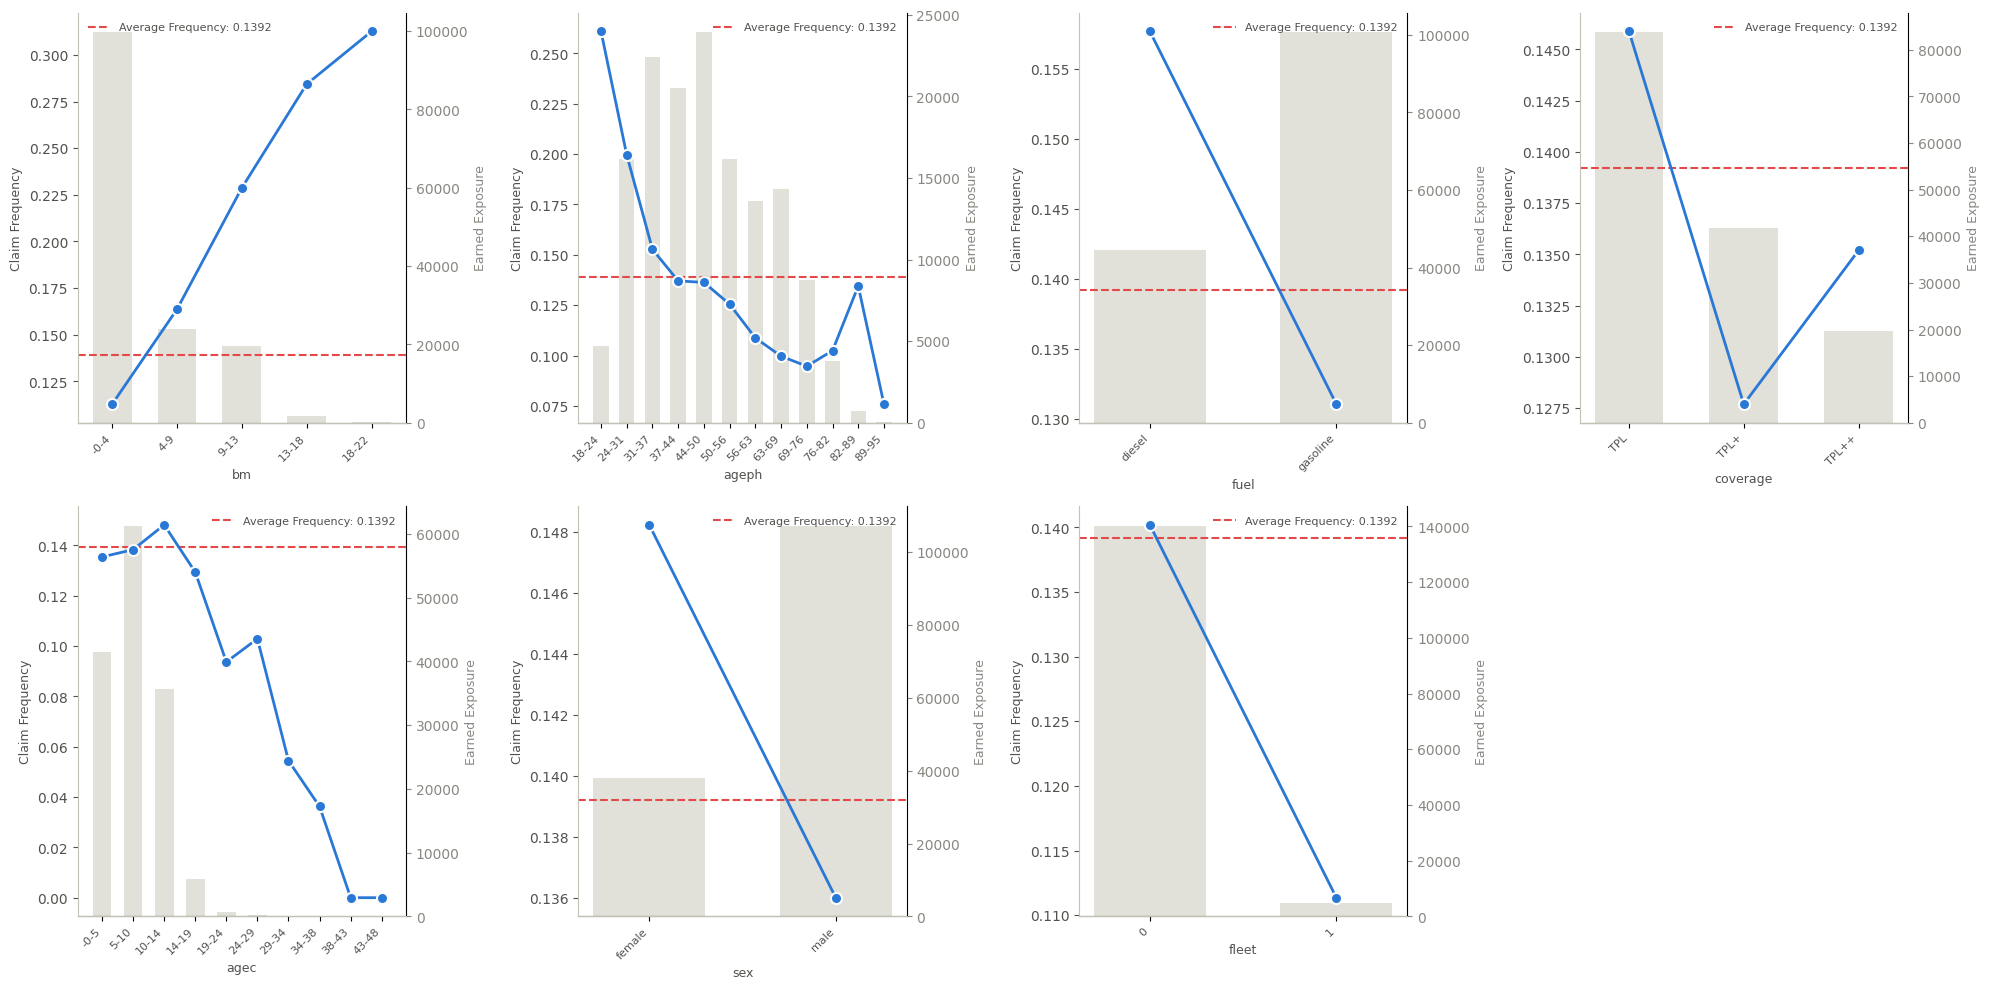

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10))

plot_frequency_by_feature(mtpl, 'bm', axs[0, 0], is_continuous=True, n_bins = 5)
plot_frequency_by_feature(mtpl, 'ageph', axs[0, 1], is_continuous=True, n_bins = 12)
plot_frequency_by_feature(mtpl, 'agec', axs[1, 0], is_continuous=True, n_bins = 10)
plot_frequency_by_feature(mtpl, 'sex', axs[1, 1], is_continuous=False, n_bins = 1)
plot_frequency_by_feature(mtpl, 'fuel', axs[0, 2], is_continuous=False, n_bins = 1)
plot_frequency_by_feature(mtpl, 'fleet', axs[1, 2], is_continuous=False, n_bins = 1)
plot_frequency_by_feature(mtpl, 'coverage', axs[0, 3], is_continuous=False, n_bins = 1)
axs[1, 3].set_visible(False)
plt.tight_layout()
plt.show()

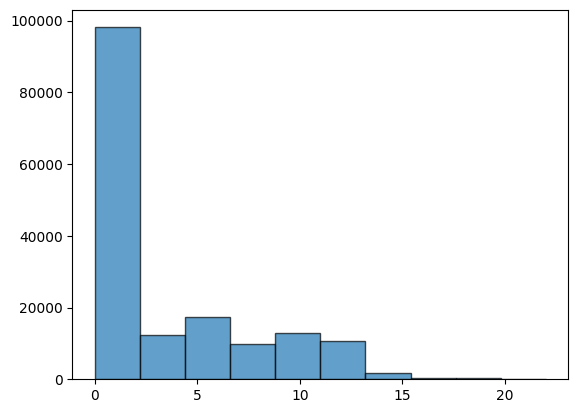

In [12]:
# Plotting Bonus Malus 

#Distribution of Bonus Malus

plt.hist(mtpl['bm'], bins=10, edgecolor='black', alpha=0.7)
plt.show()

It can be observed:

- The predictor **bm** is, naturally, a good predictor of claim frequency.

- **Age** of the driver **(Ageph)** follows a U-shape curve that is common in auto insurance since early drivers with less experience and old age people are higher risk of claims.

- **Fleet** = 1 doesn't have a lot of exposure so should probably not be so reliable

- **Diesel** cars have slightly higher frequency

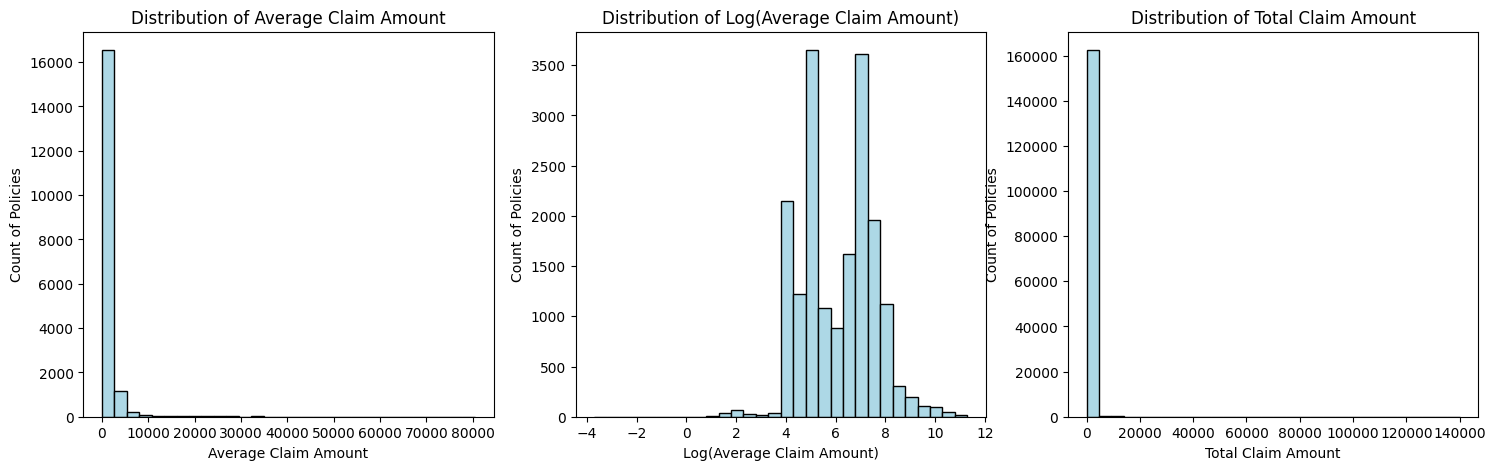

Summary Statistics of Claim Amount:
Mean             1,307.61
Median             527.42
Min                  0.02
Max             80,499.60
Variance    12,160,622.51
Name: average, dtype: object


In [13]:
# Distribution of Severity

fig, axes = plt.subplots(1,3, figsize = (18, 5))

axes[0].hist(mtpl['average'], bins = 30, color = 'lightblue', edgecolor = 'black')
axes[0].set_title('Distribution of Average Claim Amount')
axes[0].set_xlabel('Average Claim Amount')
axes[0].set_ylabel('Count of Policies')

axes[1].hist(np.log(mtpl['average']), bins = 30, color = 'lightblue', edgecolor = 'black')
axes[1].set_title('Distribution of Log(Average Claim Amount)')
axes[1].set_xlabel('Log(Average Claim Amount)')
axes[1].set_ylabel('Count of Policies')


#Distribution of Total Claim Amount 
axes[2].hist(mtpl['amount'], bins = 30, color = 'lightblue', edgecolor = 'black')
axes[2].set_title('Distribution of Total Claim Amount')
axes[2].set_xlabel('Total Claim Amount')
axes[2].set_ylabel('Count of Policies') 

plt.show()
#Summary Statistics of Average Claim Amount
print("Summary Statistics of Claim Amount:")
summary_stats = mtpl['average'].agg(['mean', 'median', 'min', 'max', 'var'])
summary_stats.index = ['Mean', 'Median', 'Min', 'Max', 'Variance']
print(summary_stats.apply(lambda x: f"{x:,.2f}"))

The distribution of Average Claim Amount is **highly right skewed** , as expected. Few people have very high claim amounts, likely because of heavy injuries. There are substantial policies with 0 claims. 

## 2. Feature Engineering 

We will now bin the continuous variables, as is standard practice before fitting GLMs in insurance pricing. This is because  
 
- It is more interpretable. (Eg age 25-30 gets a discount relative to base rate)
- It lets us capture the U-shape effect of age variable and other non-linear effects.  

### Change continuous variables to categorical 


driv_age

In [14]:
def bin_variable(data, feature, bins, labels=None):
    """Cut a continuous feature into ordered bins and store it as `<feature>_bin`."""
    data[f'{feature}_bin'] = pd.cut(data[feature], bins=bins, labels=labels, include_lowest=True)
    return data

# Bonus-malus: heavily mass at 0-1, long right tail -> finer bins at the low end
bm_bins = [-1, 0, 3, 7, 11, 22]
mtpl = bin_variable(mtpl, 'bm', bins=bm_bins,
                     labels=['0', '1-3', '4-7', '8-11', '12+'])

# Horsepower (kW): roughly bell-shaped, centered around 50-60
power_bins = [0, 40, 50, 60, 70, 80, 243]
mtpl = bin_variable(mtpl, 'power', bins=power_bins,
                     labels=['<=40', '41-50', '51-60', '61-70', '71-80', '80+'])

# Policyholder age: captures the U-shape (young + elderly = higher risk)
ageph_bins = [17, 25, 30, 35, 40, 50, 60, 70, 80, 95]
mtpl = bin_variable(mtpl, 'ageph', bins=ageph_bins,
                     labels=['18-25', '26-30', '31-35', '36-40', '41-50', '51-60', '61-70', '71-80', '81+'])

# Vehicle age: right-skewed, most cars under 12 years old
agec_bins = [-1, 1, 3, 5, 8, 12, 48]
mtpl = bin_variable(mtpl, 'agec', bins=agec_bins,
                     labels=['0-1', '2-3', '4-5', '6-8', '9-12', '13+'])

for col in ['bm_bin', 'power_bin', 'ageph_bin', 'agec_bin']:
    print(mtpl[col].value_counts().sort_index())
    print()

bm_bin
0       61647
1-3     40438
4-7     30844
8-11    25693
12+      4590
Name: count, dtype: int64

power_bin
<=40     37267
41-50    34992
51-60    38050
61-70    26593
71-80     7961
80+      18349
Name: count, dtype: int64

ageph_bin
18-25     8256
26-30    16034
31-35    18311
36-40    19280
41-50    38620
51-60    28262
61-70    22051
71-80    10924
81+       1474
Name: count, dtype: int64

agec_bin
0-1      7752
2-3     26243
4-5     25205
6-8     42927
9-12    42432
13+     18653
Name: count, dtype: int64



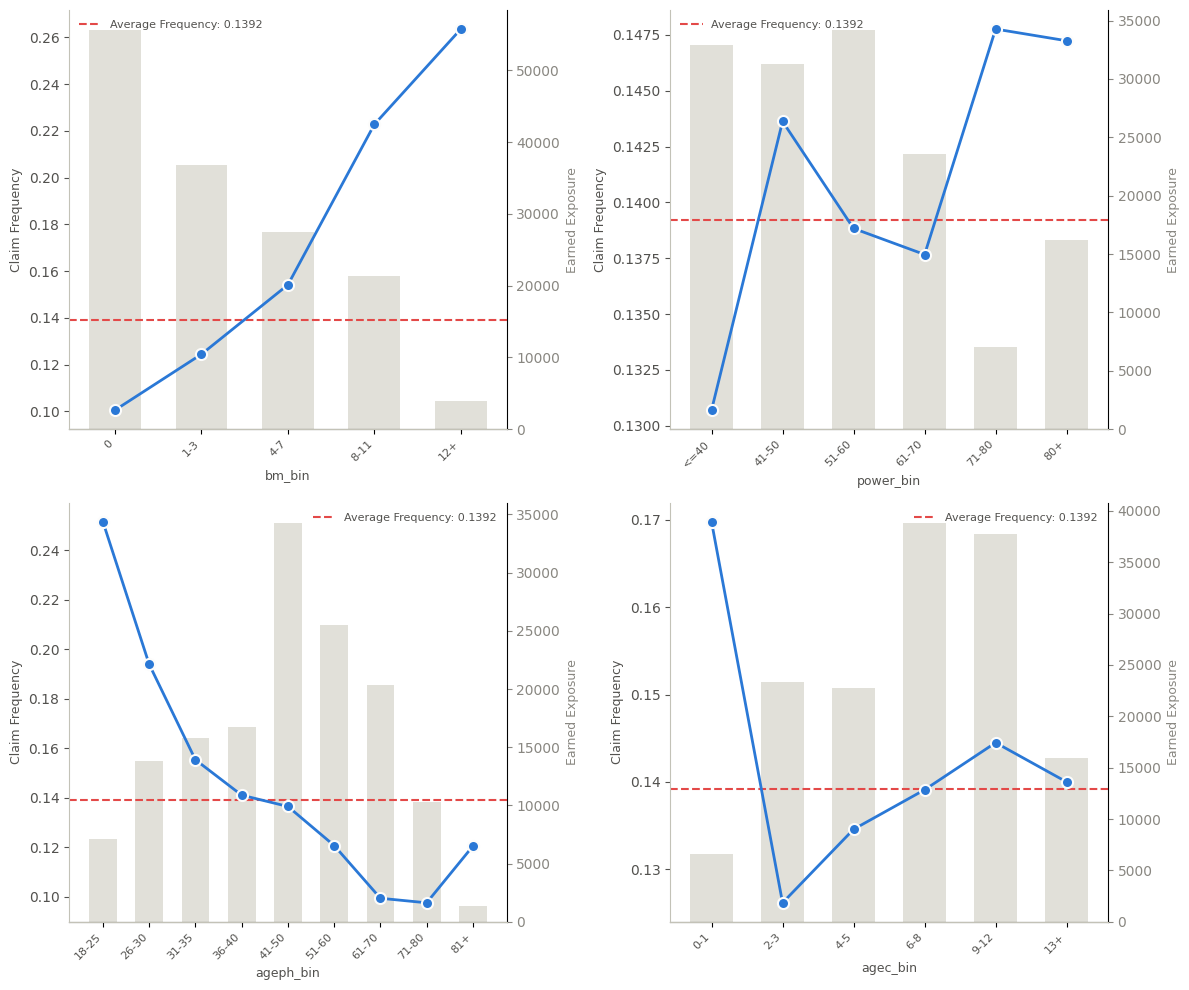

In [15]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

plot_frequency_by_feature(mtpl, 'bm_bin', axs[0, 0], is_continuous=False)
plot_frequency_by_feature(mtpl, 'power_bin', axs[0, 1], is_continuous=False)
plot_frequency_by_feature(mtpl, 'ageph_bin', axs[1, 0], is_continuous=False)
plot_frequency_by_feature(mtpl, 'agec_bin', axs[1, 1], is_continuous=False)
plt.tight_layout()
plt.show()

### Territory variable from postcode

We derive a `territory` rating factor from the leading digit of the 4-digit Belgian postal
code, which is an approximate proxy for province (Belgium has 583 unique postcodes in this
dataset, each mapping 1:1 to a municipality's lat/long centroid). This is a simplification —
real province boundaries don't align exactly with the leading digit (e.g. `1xxx` spans
Brussels, Walloon Brabant, and part of Flemish Brabant) — but it gives an interpretable,
low-cardinality geographic factor without needing a separate shapefile/mapping table.

In [16]:
territory_labels = {
    1: '1xxx - Brussels/Walloon-Brabant',
    2: '2xxx - Antwerp',
    3: '3xxx - Flemish Brabant',
    4: '4xxx - Liège',
    5: '5xxx - Namur',
    6: '6xxx - Hainaut/Luxembourg',
    7: '7xxx - Hainaut',
    8: '8xxx - West Flanders',
    9: '9xxx - East Flanders',
}
mtpl['territory'] = (mtpl['postcode'] // 1000).map(territory_labels)
mtpl['territory'].value_counts().sort_index()

territory
1xxx - Brussels/Walloon-Brabant    23649
2xxx - Antwerp                     19729
3xxx - Flemish Brabant             14706
4xxx - Liège                       21764
5xxx - Namur                        8775
6xxx - Hainaut/Luxembourg          16858
7xxx - Hainaut                     24757
8xxx - West Flanders               15899
9xxx - East Flanders               17075
Name: count, dtype: int64

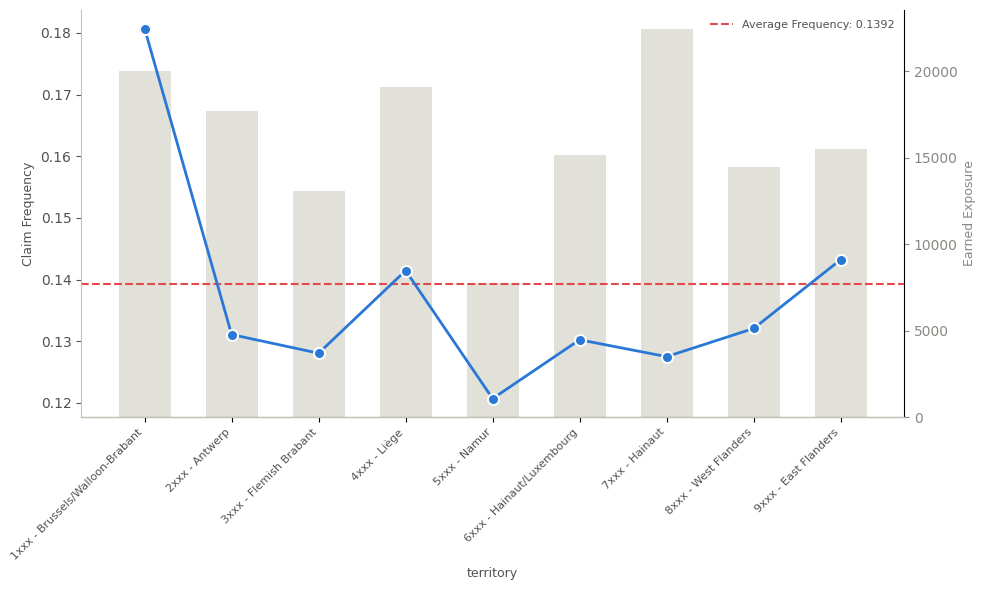

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_frequency_by_feature(mtpl, 'territory', ax, is_continuous=False)
plt.tight_layout()
plt.show()

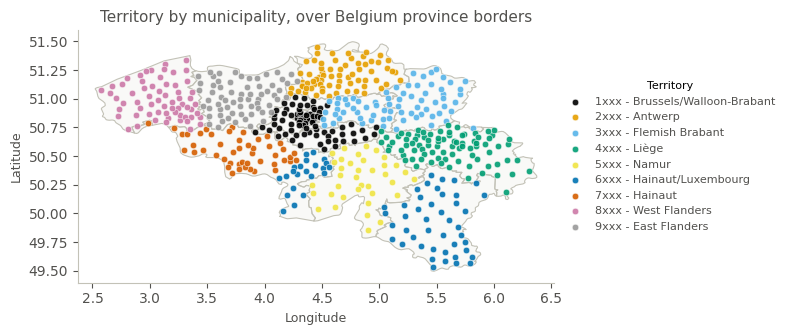

In [18]:
# Map of policyholder municipalities colored by territory, over Belgium's province
# boundaries (Natural Earth admin-1, fetched/cached by tools/fetch_belgium_provinces.py)
# Colorblind-safe qualitative palette (Okabe & Ito, 2008), extended with neutral gray for the 9th category
territory_palette = {
    '1xxx - Brussels/Walloon-Brabant': '#000000',
    '2xxx - Antwerp':                  '#E69F00',
    '3xxx - Flemish Brabant':          '#56B4E9',
    '4xxx - Liège':                    '#009E73',
    '5xxx - Namur':                    '#F0E442',
    '6xxx - Hainaut/Luxembourg':       '#0072B2',
    '7xxx - Hainaut':                  '#D55E00',
    '8xxx - West Flanders':            '#CC79A7',
    '9xxx - East Flanders':            '#999999',
}

provinces = gpd.read_file(".tmp/belgium_provinces.geojson")

# One point per postcode - all policies at a postcode share the same centroid
municipalities = mtpl.drop_duplicates('postcode')[['postcode', 'long', 'lat', 'territory']]

fig, ax = plt.subplots(figsize=(8, 9))

provinces.plot(ax=ax, color='#f9f9f7', zorder=0)
provinces.boundary.plot(ax=ax, color='#c3c2b7', linewidth=0.8, zorder=1)

for territory, color in territory_palette.items():
    subset = municipalities[municipalities['territory'] == territory]
    ax.scatter(subset['long'], subset['lat'], s=22, color=color, label=territory,
               edgecolor='#fcfcfb', linewidth=0.4, alpha=0.9, zorder=2)

ax.set_xlim(*provinces.total_bounds[[0, 2]] + [-0.15, 0.15])
ax.set_ylim(*provinces.total_bounds[[1, 3]] + [-0.1, 0.1])
ax.set_xlabel('Longitude', color=COLOR_INK, fontsize=9)
ax.set_ylabel('Latitude', color=COLOR_INK, fontsize=9)
ax.set_title('Territory by municipality, over Belgium province borders', color=COLOR_INK, fontsize=11)
ax.tick_params(colors=COLOR_INK)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
ax.set_aspect('equal')
ax.legend(fontsize=8, frameon=False, labelcolor=COLOR_INK,
          loc='center left', bbox_to_anchor=(1.0, 0.5), title='Territory', title_fontsize=8)
plt.tight_layout()
plt.show()

## 3. Modelling the Claim Frequency Using Poisson GLM with Exposure ##



The model we use is 

$$ \text{Claims} \sim \text{Poisson}(\mu)$$
$$\log{\mu} = \log{\text{Expo}} + x^T\Beta$$

In [19]:

mtpl_train, mtpl_test = train_test_split(mtpl, test_size = 0.2, random_state = 100, stratify = mtpl['claim'])

# print the number of policies
print("Number of policies in training set:", len(mtpl_train))
print("Number of policies in testing set:", len(mtpl_test)) 

#print frequency of claims in training and testing sets
train_claim_frequency = mtpl_train['nclaims'].sum() / mtpl_train['expo'].sum()
print(f"Claim frequency in training set: {train_claim_frequency:.4f}")

test_claim_frequency = mtpl_test['nclaims'].sum() / mtpl_test['expo'].sum()
print(f"Claim frequency in testing set: {test_claim_frequency:.4f}")



Number of policies in training set: 130569
Number of policies in testing set: 32643
Claim frequency in training set: 0.1392
Claim frequency in testing set: 0.1392


In [20]:
#Variables to be used for the Frequency Model

formula = ('nclaims ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) + C(sex) + C(fuel) + C(use) + C(territory)')
print("Frequency Model Formula:", formula)



Frequency Model Formula: nclaims ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) + C(sex) + C(fuel) + C(use) + C(territory)


In [21]:
#Poisson GLM with exposures

poisson_model= smf.glm(formula=formula, data=mtpl_train, family=sm.families.Poisson(), offset=np.log(mtpl_train['expo'])).fit()
print(poisson_model.summary())



                 Generalized Linear Model Regression Results                  
Dep. Variable:                nclaims   No. Observations:               130569
Model:                            GLM   Df Residuals:                   130535
Model Family:                 Poisson   Df Model:                           33
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -49901.
Date:                Thu, 12 Nov 2026   Deviance:                       69647.
Time:                        11:55:49   Pearson chi2:                 1.54e+05
No. Iterations:                     6   Pseudo R-squ. (CS):            0.01749
Covariance Type:            nonrobust                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

### Reference classes, relativities, and significance

`C(...)` treatment coding drops one level per categorical variable as the
reference (baseline) class — its effect is absorbed into the intercept, and
every other level's coefficient is a log-relativity *relative to that base*.
We recover the dropped level for each variable directly from the fitted
model (whichever category never appears as a `[T....]` parameter), then
convert each remaining coefficient to a relativity `exp(coef)` and flag
whether it's statistically significant at the 5% level.

In [22]:
import re

categorical_vars = ['bm_bin', 'power_bin', 'ageph_bin', 'agec_bin', 'sex', 'fuel', 'use', 'territory']

rows = []
for var in categorical_vars:
    pattern = re.compile(rf"^C\({re.escape(var)}\)\[T\.(.+)\]$")
    levels_in_model = {}
    for name in poisson_model.params.index:
        match = pattern.match(name)
        if match:
            levels_in_model[match.group(1)] = name

    col = mtpl_train[var]
    all_levels = list(col.cat.categories) if hasattr(col, 'cat') else sorted(col.unique())
    reference = next(lvl for lvl in all_levels if lvl not in levels_in_model)

    rows.append({'variable': var, 'level': reference, 'reference': True,
                 'coef': 0.0, 'relativity': 1.0, 'p_value': np.nan})
    for lvl in all_levels:
        if lvl == reference:
            continue
        param = levels_in_model[lvl]
        rows.append({'variable': var, 'level': lvl, 'reference': False,
                     'coef': poisson_model.params[param],
                     'relativity': np.exp(poisson_model.params[param]),
                     'p_value': poisson_model.pvalues[param]})

relativities = pd.DataFrame(rows)
relativities['significant'] = np.where(
    relativities['reference'], 'reference',
    np.where(relativities['p_value'] < 0.05, 'Yes', 'No')
)

print("Reference (base) classes:")
for var in categorical_vars:
    ref_level = relativities.loc[(relativities['variable'] == var) & relativities['reference'], 'level'].iloc[0]
    print(f"  {var}: {ref_level}")

pd.set_option('display.max_rows', None)
relativities[['variable', 'level', 'coef', 'relativity', 'p_value', 'significant']].round(4)

Reference (base) classes:
  bm_bin: 0
  power_bin: <=40
  ageph_bin: 18-25
  agec_bin: 0-1
  sex: female
  fuel: diesel
  use: private
  territory: 1xxx - Brussels/Walloon-Brabant


,variable,level,coef,relativity,p_value,significant
0,bm_bin,0,0.0000,1.0000,NaN,reference
1,bm_bin,1-3,0.1686,1.1836,0.0000,Yes
2,bm_bin,4-7,0.3374,1.4013,0.0000,Yes
3,bm_bin,8-11,0.6100,1.8405,0.0000,Yes
4,bm_bin,12+,0.7927,2.2094,0.0000,Yes
5,power_bin,<=40,0.0000,1.0000,NaN,reference
6,power_bin,41-50,0.0941,1.0987,0.0001,Yes
7,power_bin,51-60,0.1165,1.1236,0.0000,Yes
8,power_bin,61-70,0.1122,1.1187,0.0000,Yes
9,power_bin,71-80,0.2351,1.2651,0.0000,Yes


### Top 4 highest-impact categories per variable

For each variable we rank its non-reference categories by `|coefficient|` (how far
they swing from that variable's own reference class, in either direction) and keep
the top 4. 

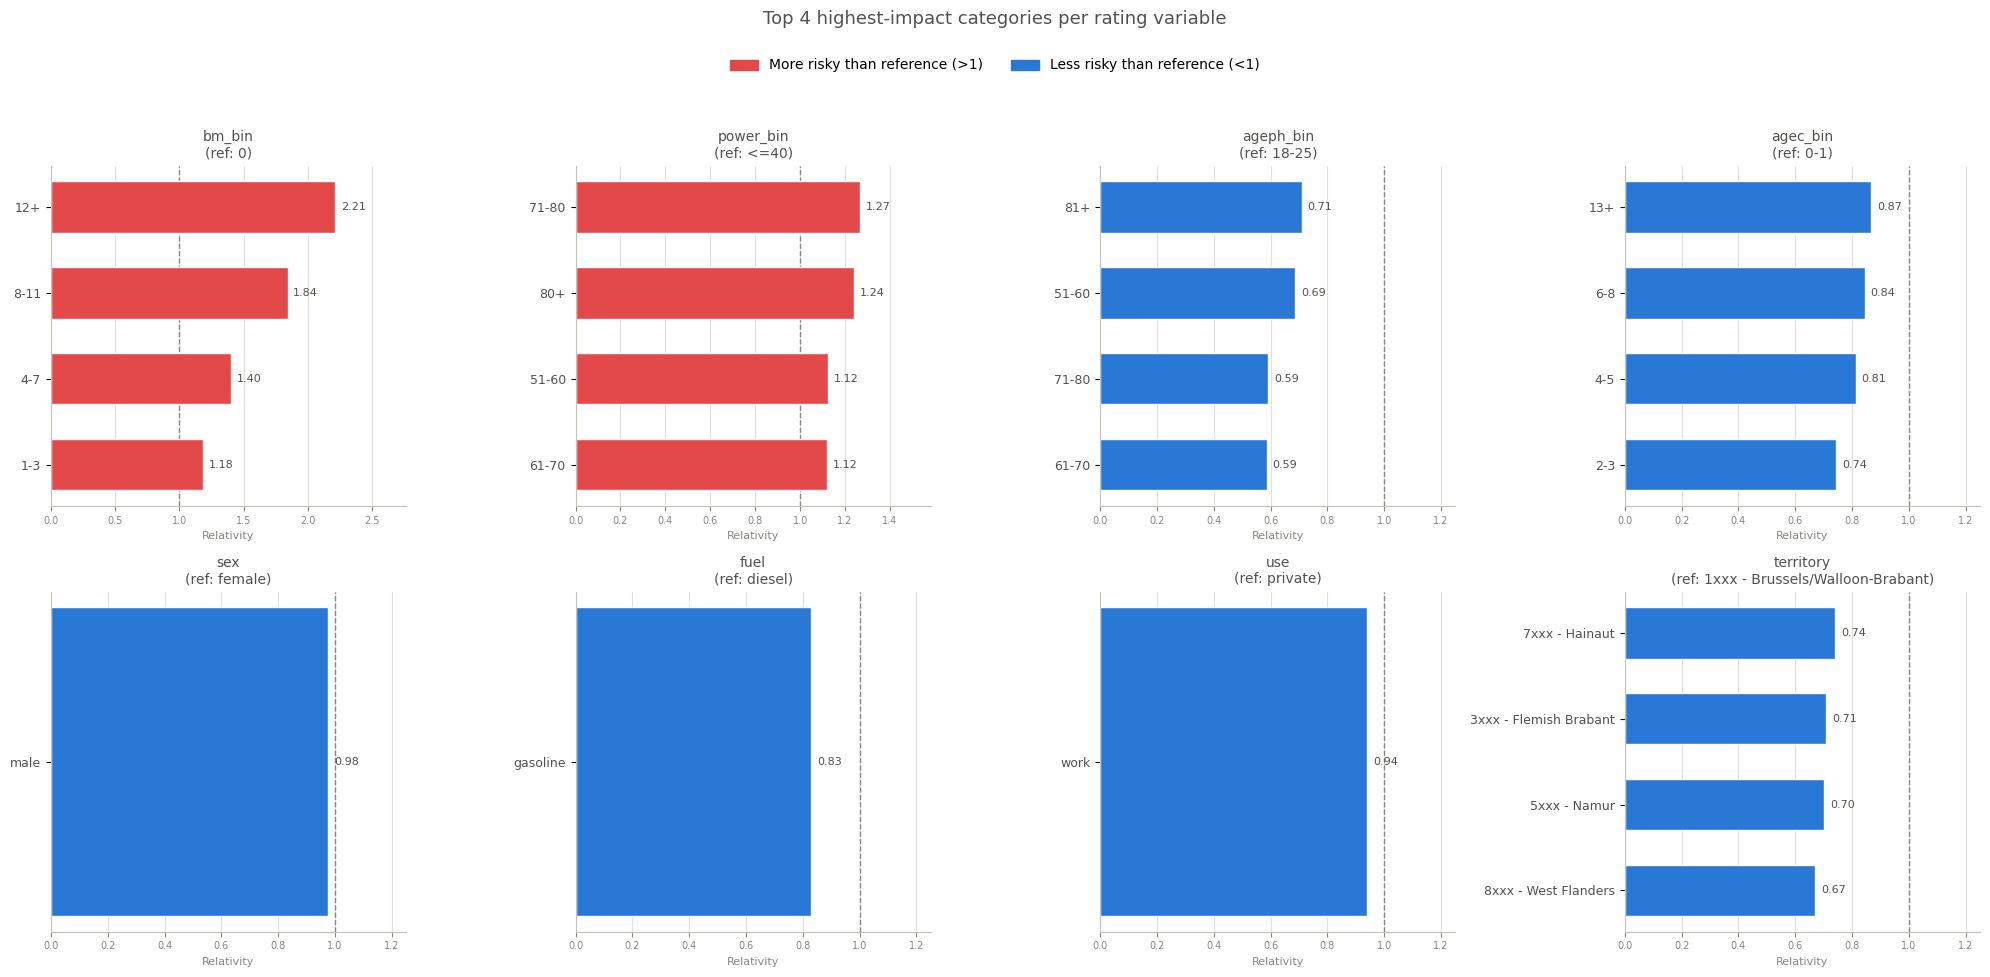

In [23]:
top_n = 4
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
axs = axs.flatten()

for ax, var in zip(axs, categorical_vars):
    ref_level = relativities.loc[(relativities['variable'] == var) & relativities['reference'], 'level'].iloc[0]
    sub = relativities[(relativities['variable'] == var) & (~relativities['reference'])].copy()
    sub['abs_coef'] = sub['coef'].abs()
    sub = sub.sort_values('abs_coef', ascending=False).head(top_n)
    sub = sub.sort_values('relativity')

    colors = [COLOR_AVG if r > 1 else COLOR_LINE for r in sub['relativity']]
    y_pos = range(len(sub))
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color='#e1e0d9', linewidth=0.8)
    ax.barh(y_pos, sub['relativity'], color=colors, edgecolor='#fcfcfb', height=0.6, zorder=2)
    ax.axvline(1.0, color=COLOR_MUTED, linestyle='--', linewidth=1, zorder=1)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(sub['level'], fontsize=9, color=COLOR_INK)
    for i, rel in enumerate(sub['relativity']):
        offset = 0.02 * max(sub['relativity'].max(), 1)
        ax.text(rel + offset, i, f'{rel:.2f}', va='center', fontsize=8, color=COLOR_INK)
    ax.set_title(f'{var}\n(ref: {ref_level})', fontsize=10, color=COLOR_INK)
    ax.set_xlabel('Relativity', fontsize=8, color=COLOR_MUTED)
    ax.tick_params(axis='x', colors=COLOR_MUTED, labelsize=7)
    ax.set_xlim(0, max(sub['relativity'].max(), 1) * 1.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#c3c2b7')

handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR_AVG), plt.Rectangle((0, 0), 1, 1, color=COLOR_LINE)]
fig.legend(handles, ['More risky than reference (>1)', 'Less risky than reference (<1)'],
           loc='upper center', ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.04))
fig.suptitle('Top 4 highest-impact categories per rating variable', fontsize=13, color=COLOR_INK, y=1.08)
plt.tight_layout()
plt.show()

Each $\beta$ coefficient was converted to its relativity factor by exponentiating. For instance, a 12+ b-m score indicates a $121\%$ greater frequency than the base bm of 0. We should note that the **use** variable and sex variable don't have significant coefficients. 

Now we check the dispersion to see if a Poission model was appropriate. 

In [24]:
pearson = poisson_model.pearson_chi2 / poisson_model.df_resid

deviance_dispersion = poisson_model.deviance / poisson_model.df_resid

print(f'Dispersion diagnostics:')
print(f'  Pearson dispersion:  {pearson:.4f}')
print(f'  Deviance dispersion: {deviance_dispersion:.4f}')

Dispersion diagnostics:
  Pearson dispersion:  1.1784
  Deviance dispersion: 0.5336


The dispersion statistics are close to 1, indicating the Poisson model would be okay 

### Variable Selection for Frequency Model

Now we decide which factors to keep

In [25]:
poisson_model.llf


def remove_factor(original_model, factor, alpha):
    reduced_formula = 'nclaims ~ ' + ' + '.join(
        term.strip() for term in formula.split('~')[1].split('+')
        if term.strip() != f'C({factor})'
    )
    reduced_model = smf.glm(formula=reduced_formula, data=mtpl_train,
                             family=sm.families.Poisson(),
                             offset=np.log(mtpl_train['expo'])).fit()

    lr = 2*(original_model.llf - reduced_model.llf)
    col = mtpl_train[factor]
    k = (len(col.cat.categories) if hasattr(col, 'cat') else col.nunique()) - 1

    p = stats.chi2.sf(lr, k)

    if p < alpha:
        return False  # Reject the null hypothesis
    else:
        return True   # Accept the null hypothesis


for factor in categorical_vars:
    result = remove_factor(poisson_model, factor, alpha=0.05)
    if result:
        print(f"Factor '{factor}' can be removed (p >= 0.05).")
    else:
        print(f"Factor '{factor}' is significant and should be retained (p < 0.05).")

Factor 'bm_bin' is significant and should be retained (p < 0.05).


Factor 'power_bin' is significant and should be retained (p < 0.05).


Factor 'ageph_bin' is significant and should be retained (p < 0.05).


Factor 'agec_bin' is significant and should be retained (p < 0.05).


Factor 'sex' can be removed (p >= 0.05).


Factor 'fuel' is significant and should be retained (p < 0.05).


Factor 'use' can be removed (p >= 0.05).


Factor 'territory' is significant and should be retained (p < 0.05).


In [26]:
poisson_model_formula_new = ('nclaims ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) +  C(fuel) + C(use) + C(territory)')
poisson_model_new= smf.glm(formula=poisson_model_formula_new, data=mtpl_train, family=sm.families.Poisson(), offset=np.log(mtpl_train['expo'])).fit()



for factor in [f for f in categorical_vars if f != 'sex']:
    result = remove_factor(poisson_model_new, factor, alpha=0.05)
    if result:
        print(f"Factor '{factor}' can be removed (p >= 0.05).")
    else:
        print(f"Factor '{factor}' is significant and should be retained (p < 0.05).")


Factor 'bm_bin' is significant and should be retained (p < 0.05).


Factor 'power_bin' is significant and should be retained (p < 0.05).


Factor 'ageph_bin' is significant and should be retained (p < 0.05).


Factor 'agec_bin' is significant and should be retained (p < 0.05).


Factor 'fuel' is significant and should be retained (p < 0.05).


Factor 'use' can be removed (p >= 0.05).


Factor 'territory' is significant and should be retained (p < 0.05).


So we remove use as well. The final model formula is:

In [27]:
formula_final = ('nclaims ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) +C(fuel)  + C(territory)')
print("Frequency Model Formula:", formula_final)

Frequency Model Formula: nclaims ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) +C(fuel)  + C(territory)


In [28]:
#Poisson GLM with exposures - final model

final_model = smf.glm(formula=formula_final, data=mtpl_train, family=sm.families.Poisson(), offset=np.log(mtpl_train['expo'])).fit()
print(final_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                nclaims   No. Observations:               130569
Model:                            GLM   Df Residuals:                   130537
Model Family:                 Poisson   Df Model:                           31
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -49903.
Date:                Thu, 12 Nov 2026   Deviance:                       69652.
Time:                        11:56:17   Pearson chi2:                 1.54e+05
No. Iterations:                     6   Pseudo R-squ. (CS):            0.01746
Covariance Type:            nonrobust                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [29]:
pearson_final = final_model.pearson_chi2 / final_model.df_resid
deviance_dispersion_final = final_model.deviance / final_model.df_resid

print(f'Dispersion diagnostics (final model):')
print(f'  Pearson dispersion:  {pearson_final:.4f}')
print(f'  Deviance dispersion: {deviance_dispersion_final:.4f}')

Dispersion diagnostics (final model):
  Pearson dispersion:  1.1787
  Deviance dispersion: 0.5336


## 4. Severity Model: Gamma GLM

In [30]:
# filter for policies where claim occured

mtpl_train_sev = mtpl_train[mtpl_train['claim'] ==1].copy()
mtpl_test_sev = mtpl_test[mtpl_test['claim'] ==1 ].copy()

print("Number of policies in training set (severity):", len(mtpl_train_sev))
print("Number of policies in testing set (severity):", len(mtpl_test_sev))
print(f'\nAvg claim amount in training set (severity): {mtpl_train_sev["average"].mean():.2f}')
print(f'Avg claim amount in testing set (severity): {mtpl_test_sev["average"].mean():.2f}')


Number of policies in training set (severity): 14621
Number of policies in testing set (severity): 3655

Avg claim amount in training set (severity): 1277.80
Avg claim amount in testing set (severity): 1426.88


The model we use is

$$ \text{Average} \sim \text{Gamma}(\mu, \phi)$$
$$\log{\mu} = x^T\Beta$$

In [31]:
#Variables to be used for the Severity Model - sex excluded (prohibited rating factor); otherwise start with all predictors

formula_severity = ('average ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) + C(fuel) + C(use) + C(territory)')
print("Severity Model Formula:", formula_severity)

Severity Model Formula: average ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) + C(fuel) + C(use) + C(territory)


In [32]:
#Gamma GLM with log link
#average = amount / nclaims, so each row's variance is scaled down by its own nclaims -
#weighting by nclaims (var_weights) accounts for this so policies with more claims count more

severity_model = smf.glm(formula=formula_severity, data=mtpl_train_sev,
                          family=sm.families.Gamma(link=sm.families.links.Log()),
                          var_weights=mtpl_train_sev['nclaims']).fit()
print(severity_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                average   No. Observations:                14621
Model:                            GLM   Df Residuals:                    14588
Model Family:                   Gamma   Df Model:                           32
Link Function:                    Log   Scale:                          6.1185
Method:                          IRLS   Log-Likelihood:            -1.2337e+05
Date:                Thu, 12 Nov 2026   Deviance:                       31938.
Time:                        11:56:17   Pearson chi2:                 8.93e+04
No. Iterations:                    17   Pseudo R-squ. (CS):           0.005655
Covariance Type:            nonrobust                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [33]:
pearson_severity = severity_model.pearson_chi2 / severity_model.df_resid
deviance_dispersion_severity = severity_model.deviance / severity_model.df_resid

print(f'Dispersion diagnostics (severity model):')
print(f'  Pearson dispersion:  {pearson_severity:.4f}')
print(f'  Deviance dispersion: {deviance_dispersion_severity:.4f}')

Dispersion diagnostics (severity model):
  Pearson dispersion:  6.1185
  Deviance dispersion: 2.1893


In [34]:

categorical_vars = ['bm_bin', 'power_bin', 'ageph_bin', 'agec_bin', 'fuel', 'use', 'territory']

rows = []
for var in categorical_vars:
    pattern = re.compile(rf"^C\({re.escape(var)}\)\[T\.(.+)\]$")
    levels_in_model = {}
    for name in severity_model.params.index:
        match = pattern.match(name)
        if match:
            levels_in_model[match.group(1)] = name

    col = mtpl_train[var]
    all_levels = list(col.cat.categories) if hasattr(col, 'cat') else sorted(col.unique())
    reference = next(lvl for lvl in all_levels if lvl not in levels_in_model)

    rows.append({'variable': var, 'level': reference, 'reference': True,
                 'coef': 0.0, 'relativity': 1.0, 'p_value': np.nan})
    for lvl in all_levels:
        if lvl == reference:
            continue
        param = levels_in_model[lvl]
        rows.append({'variable': var, 'level': lvl, 'reference': False,
                     'coef': severity_model.params[param],
                     'relativity': np.exp(severity_model.params[param]),
                     'p_value': severity_model.pvalues[param]})

relativities = pd.DataFrame(rows)
relativities['significant'] = np.where(
    relativities['reference'], 'reference',
    np.where(relativities['p_value'] < 0.05, 'Yes', 'No')
)

print("Reference (base) classes:")
for var in categorical_vars:
    ref_level = relativities.loc[(relativities['variable'] == var) & relativities['reference'], 'level'].iloc[0]
    print(f"  {var}: {ref_level}")

pd.set_option('display.max_rows', None)
relativities[['variable', 'level', 'coef', 'relativity', 'p_value', 'significant']].round(4)

Reference (base) classes:
  bm_bin: 0
  power_bin: <=40
  ageph_bin: 18-25
  agec_bin: 0-1
  fuel: diesel
  use: private
  territory: 1xxx - Brussels/Walloon-Brabant


,variable,level,coef,relativity,p_value,significant
0,bm_bin,0,0.0000,1.0000,NaN,reference
1,bm_bin,1-3,0.1211,1.1287,0.0300,Yes
2,bm_bin,4-7,0.1161,1.1231,0.0458,Yes
3,bm_bin,8-11,0.1261,1.1344,0.0457,Yes
4,bm_bin,12+,0.0584,1.0602,0.5513,No
5,power_bin,<=40,0.0000,1.0000,NaN,reference
6,power_bin,41-50,-0.0298,0.9706,0.6238,No
7,power_bin,51-60,-0.1263,0.8813,0.0342,Yes
8,power_bin,61-70,-0.0770,0.9259,0.2501,No
9,power_bin,71-80,-0.0324,0.9681,0.7390,No


### Top 4 highest-impact categories per variable

Same approach as the frequency model: for each variable we rank its
non-reference categories by `|coefficient|` (how far they swing from that
variable's own reference class, in either direction) and keep the top 4.

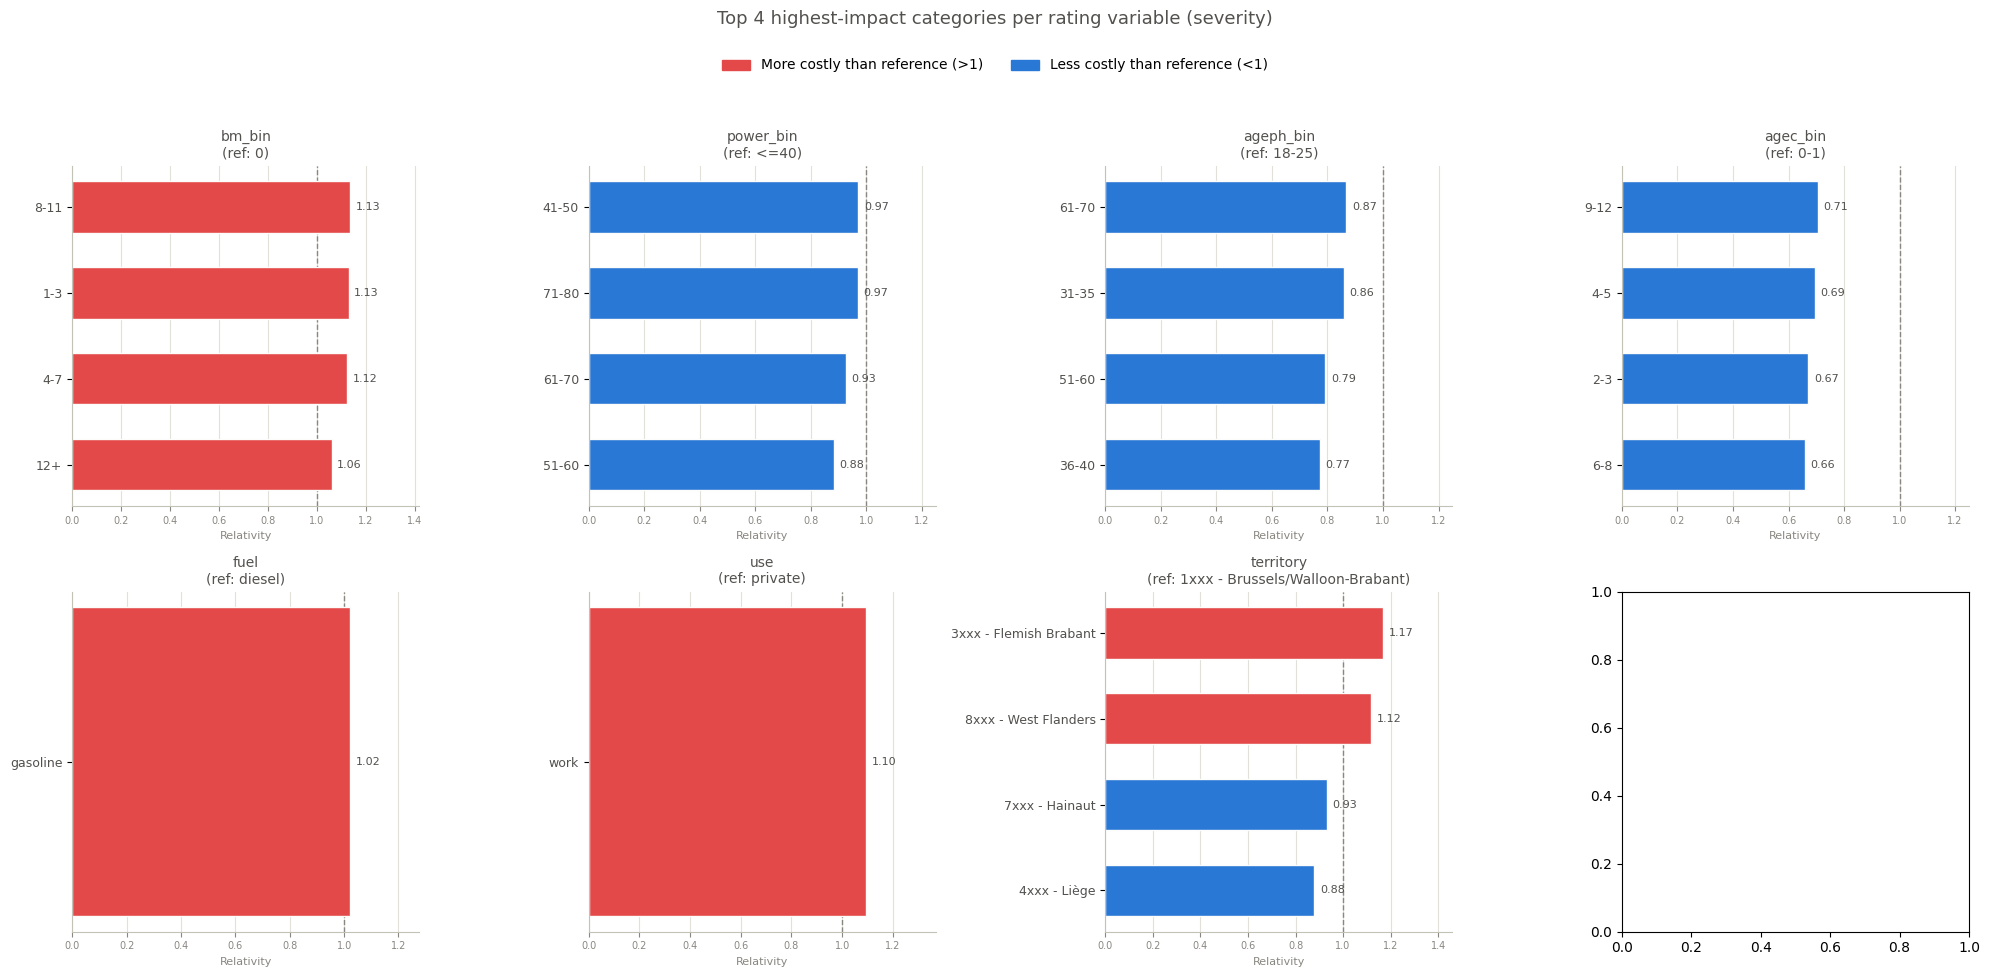

In [35]:
top_n = 4
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
axs = axs.flatten()

for ax, var in zip(axs, categorical_vars):
    ref_level = relativities.loc[(relativities['variable'] == var) & relativities['reference'], 'level'].iloc[0]
    sub = relativities[(relativities['variable'] == var) & (~relativities['reference'])].copy()
    sub['abs_coef'] = sub['coef'].abs()
    sub = sub.sort_values('abs_coef', ascending=False).head(top_n)
    sub = sub.sort_values('relativity')

    colors = [COLOR_AVG if r > 1 else COLOR_LINE for r in sub['relativity']]
    y_pos = range(len(sub))
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color='#e1e0d9', linewidth=0.8)
    ax.barh(y_pos, sub['relativity'], color=colors, edgecolor='#fcfcfb', height=0.6, zorder=2)
    ax.axvline(1.0, color=COLOR_MUTED, linestyle='--', linewidth=1, zorder=1)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(sub['level'], fontsize=9, color=COLOR_INK)
    for i, rel in enumerate(sub['relativity']):
        offset = 0.02 * max(sub['relativity'].max(), 1)
        ax.text(rel + offset, i, f'{rel:.2f}', va='center', fontsize=8, color=COLOR_INK)
    ax.set_title(f'{var}\n(ref: {ref_level})', fontsize=10, color=COLOR_INK)
    ax.set_xlabel('Relativity', fontsize=8, color=COLOR_MUTED)
    ax.tick_params(axis='x', colors=COLOR_MUTED, labelsize=7)
    ax.set_xlim(0, max(sub['relativity'].max(), 1) * 1.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#c3c2b7')

handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR_AVG), plt.Rectangle((0, 0), 1, 1, color=COLOR_LINE)]
fig.legend(handles, ['More costly than reference (>1)', 'Less costly than reference (<1)'],
           loc='upper center', ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.04))
fig.suptitle('Top 4 highest-impact categories per rating variable (severity)', fontsize=13, color=COLOR_INK, y=1.08)
plt.tight_layout()
plt.show()

Car age (`agec_bin`) drives the largest swings in severity: every age band beyond 0-1 years is associated with roughly $28\%$-$34\%$ **lower** average claim cost, and all are statistically significant. Bonus-malus score shows the opposite pattern from frequency's magnitude but a similar direction, with higher bm bands associated with modestly higher severity (e.g. the 8-11 band is about $14\%$ more costly than bm 0). **sex** has been excluded from the severity model entirely as a prohibited rating factor under many regulatory regimes (e.g. the EU Gender Directive); **fuel** and **use** remain in the model but, as with frequency, are not statistically significant for severity.

## 5. Pure Premium Calculation

Now we multiply Severity and Frequency to predict the Pure Premium per policy

$$ \text{Pure Premium}= \text{Frequency} \times \text{Severity} $$

In [36]:
# Predicted frequency (expected claims per unit exposure) from the final Poisson model
# -- predict() with no offset argument returns exp(X*beta), i.e. the annualized rate
mtpl_test['pred_frequency'] = final_model.predict(mtpl_test)

# Predicted severity (expected cost per claim) from the Gamma model
mtpl_test['pred_severity'] = severity_model.predict(mtpl_test)

# Pure premium = frequency x severity, i.e. expected annualized claims cost per policy
mtpl_test['pred_pure_premium'] = mtpl_test['pred_frequency'] * mtpl_test['pred_severity']

# Scale by each policy's actual exposure to get predicted claims cost over its observed period,
# so it's directly comparable to the observed `amount` column
mtpl_test['pred_amount'] = mtpl_test['pred_pure_premium'] * mtpl_test['expo']

## Actual total premium 

total_premium_actual = mtpl_test['amount'].sum()
predicted_total_premium = mtpl_test['pred_amount'].sum()

print(f"Total actual premium: {total_premium_actual:.2f}")
print(f"Total predicted premium: {predicted_total_premium:.2f}")

print(f"Average predicted pure premium per policy (annualized): {mtpl_test['pred_pure_premium'].mean():.2f}")


mtpl_test[['id', 'expo', 'pred_frequency', 'pred_severity', 'pred_pure_premium', 'pred_amount', 'amount']].head(10)

Total actual premium: 5819324.09
Total predicted premium: 5196729.52
Average predicted pure premium per policy (annualized): 181.88


,id,expo,pred_frequency,pred_severity,pred_pure_premium,pred_amount,amount
54429,54430,1.000000,0.119139,1555.542448,185.325543,185.325543,1943.014237
20752,20753,0.221918,0.163151,1125.778191,183.672266,40.760147,0.000000
34490,34491,0.715068,0.172685,1289.971541,222.758717,159.287740,0.000000
31168,31169,1.000000,0.115548,1127.018024,130.225180,130.225180,0.000000
27666,27667,1.000000,0.091289,1480.357929,135.140360,135.140360,0.000000
29021,29022,1.000000,0.091115,1035.696947,94.367359,94.367359,0.000000
117815,117816,1.000000,0.111560,1033.331839,115.278720,115.278720,0.000000
36789,36790,1.000000,0.072531,1162.783931,84.338411,84.338411,0.000000
116638,116639,1.000000,0.093827,1089.206907,102.197234,102.197234,0.000000
74763,74764,1.000000,0.250358,1388.564651,347.638443,347.638443,0.000000


`pred_frequency` comes from the final (reduced) Poisson model and `pred_severity` from the Gamma model, both evaluated on `mtpl_test`; their product is the pure premium — the expected annualized claims cost per policy before any loadings for expenses or profit. The portfolio-level calibration ratio compares the test set's total predicted claims cost to its total actual claims cost, which should sit close to 1.0 if the two-part model is well calibrated out of sample.

## 6. Tweedie GLM

Now we fit a tweedie GLM to model the pure premium directly 

In [37]:
mtpl_tweedie = mtpl_train.copy()
mtpl_tweedie['PurePremium'] = mtpl_tweedie['amount'] / mtpl_tweedie['expo']


form_tweedie = 'PurePremium ~ C(bm_bin) + C(power_bin) + C(ageph_bin) + C(agec_bin) + C(fuel) + C(use) + C(territory)'

power_values = [1.1, 1.3, 1.5, 1.7, 1.9]
tweedie_results = []

for p in power_values:
    tw_model = smf.glm(
        formula=form_tweedie,
        data=mtpl_tweedie,
        family=Tweedie(link=Log(), var_power=p),
        freq_weights=mtpl_tweedie['expo']
    ).fit()
    tweedie_results.append({
        'power': p,
        'deviance': tw_model.deviance,
        'aic': tw_model.aic,
        'model': tw_model
    })
    print(f'  Power={p:.1f}  Deviance={tw_model.deviance:,.1f}  AIC={tw_model.aic:,.1f}')


best_tw = min(tweedie_results, key=lambda x: x['deviance'])
print(f'\nBest Tweedie power: {best_tw["power"]} (lowest deviance)')

  Power=1.1  Deviance=71,288,806.8  AIC=943,847.1


  Power=1.3  Deviance=23,323,296.5  AIC=456,439.5


  Power=1.5  Deviance=8,843,303.6  AIC=364,786.7


  Power=1.7  Deviance=4,193,484.3  AIC=329,899.8


  Power=1.9  Deviance=3,724,671.0  AIC=323,557.3

Best Tweedie power: 1.9 (lowest deviance)


### Tweedie vs Freq x Severity Model Comparison

In [38]:
# Predict pure premium on the test set with the selected Tweedie model (lowest deviance, power = 1.9)
tweedie_model = best_tw['model']
print(f"Selected Tweedie model: var_power = {best_tw['power']}")

mtpl_test['pred_pure_premium_tweedie'] = tweedie_model.predict(mtpl_test)
mtpl_test['pred_amount_tweedie'] = mtpl_test['pred_pure_premium_tweedie'] * mtpl_test['expo']

mtpl_test.head()


# ---- Totals comparison: Frequency x Severity vs Tweedie ----
# Total Premium: sum of each policy's annualized pure premium rate (full-term technical premium)
# Predicted Claim Amount: that rate scaled to each policy's actual observed exposure
# Total Cost / Total Claim Amount: the actual observed claims cost (ground truth, same for both models)
actual_amount = mtpl_test['amount'].sum()
predicted_fs = mtpl_test['pred_amount'].sum()
predicted_tweedie = mtpl_test['pred_amount_tweedie'].sum()

totals = pd.DataFrame({
    'Frequency x Severity': {

        'Predicted Claim Amount': predicted_fs,
        'Total Claim Amount (actual)': actual_amount,
        'Ratio': predicted_fs / actual_amount,
    },
    'Tweedie': {
        'Predicted Claim Amount': predicted_tweedie,
        'Total Claim Amount (actual)': actual_amount,
        'Ratio': predicted_tweedie / actual_amount,
    },
})

totals.round(2)
totals.round(2)


Selected Tweedie model: var_power = 1.9


,Frequency x Severity,Tweedie
Predicted Claim Amount,5196729.52,5222295.98
Total Claim Amount (actual),5819324.09,5819324.09
Ratio,0.89,0.90


The ratio for both approaches is almost the same. 

In [39]:
# ---- Relativity comparison: Tweedie vs. the implied Frequency x Severity relativity ----
# Use the full (unreduced) frequency and severity models so the variable set matches the Tweedie
# model's formula exactly (both include use, unlike the reduced final_model; sex is excluded from every model).

def get_relativities(model, data, categorical_vars):
    rows = []
    for var in categorical_vars:
        pattern = re.compile(rf"^C\({re.escape(var)}\)\[T\.(.+)\]$")
        levels_in_model = {}
        for name in model.params.index:
            match = pattern.match(name)
            if match:
                levels_in_model[match.group(1)] = name
        col = data[var]
        all_levels = list(col.cat.categories) if hasattr(col, 'cat') else sorted(col.unique())
        reference = next(lvl for lvl in all_levels if lvl not in levels_in_model)
        rows.append({'variable': var, 'level': reference, 'relativity': 1.0})
        for lvl in all_levels:
            if lvl == reference:
                continue
            param = levels_in_model[lvl]
            rows.append({'variable': var, 'level': lvl, 'relativity': np.exp(model.params[param])})
    return pd.DataFrame(rows)

freq_rel = get_relativities(poisson_model, mtpl_train, categorical_vars).rename(columns={'relativity': 'freq_relativity'})
sev_rel = get_relativities(severity_model, mtpl_train, categorical_vars).rename(columns={'relativity': 'sev_relativity'})
tw_rel = get_relativities(tweedie_model, mtpl_train, categorical_vars).rename(columns={'relativity': 'tweedie_relativity'})

rel_compare = freq_rel.merge(sev_rel, on=['variable', 'level']).merge(tw_rel, on=['variable', 'level'])
rel_compare['combined_freq_x_sev'] = rel_compare['freq_relativity'] * rel_compare['sev_relativity']
rel_compare = rel_compare[['variable', 'level', 'freq_relativity', 'sev_relativity', 'combined_freq_x_sev', 'tweedie_relativity']]

pd.set_option('display.max_rows', None)
rel_compare.round(3)

,variable,level,freq_relativity,sev_relativity,combined_freq_x_sev,tweedie_relativity
0,bm_bin,0,1.000,1.000,1.000,1.000
1,bm_bin,1-3,1.184,1.129,1.336,1.361
2,bm_bin,4-7,1.401,1.123,1.574,1.559
3,bm_bin,8-11,1.840,1.134,2.088,2.110
4,bm_bin,12+,2.209,1.060,2.342,2.381
5,power_bin,<=40,1.000,1.000,1.000,1.000
6,power_bin,41-50,1.099,0.971,1.066,1.054
7,power_bin,51-60,1.124,0.881,0.990,0.955
8,power_bin,61-70,1.119,0.926,1.036,0.972
9,power_bin,71-80,1.265,0.968,1.225,1.190


`combined_freq_x_sev` is the two-part model's implied pure-premium relativity — frequency relativity times severity relativity for each category, relative to that variable's reference class. `tweedie_relativity` is the same thing read directly off the single Tweedie GLM fit on `PurePremium`. Where the two columns track closely, the one-part and two-part approaches agree on relative risk; a wide gap flags a variable where splitting frequency and severity picks up something the single-stage Tweedie model smooths over (or vice versa).

In [40]:
## Creating a Rating Table for the Final Poission Frequence, Severity and Tweedie Models

def build_rating_table(model, data, categorical_vars):
    rows = []
    for var in categorical_vars:
        pattern = re.compile(rf"^C\({re.escape(var)}\)\[T\.(.+)\]$")
        levels_in_model = {}
        for name in model.params.index:
            match = pattern.match(name)
            if match:
                levels_in_model[match.group(1)] = name
        col = data[var]
        all_levels = list(col.cat.categories) if hasattr(col, 'cat') else sorted(col.unique())
        reference = next(lvl for lvl in all_levels if lvl not in levels_in_model)
        rows.append({'variable': var, 'level': reference, 'reference': True,
                     'coef': 0.0, 'relativity': 1.0, 'p_value': np.nan})
        for lvl in all_levels:
            if lvl == reference:
                continue
            param = levels_in_model[lvl]
            rows.append({'variable': var, 'level': lvl, 'reference': False,
                         'coef': model.params[param],
                         'relativity': np.exp(model.params[param]),
                         'p_value': model.pvalues[param]})
    df = pd.DataFrame(rows)
    df['significant'] = np.where(df['reference'], 'reference', np.where(df['p_value'] < 0.05, 'Yes', 'No'))
    return df

# sex is excluded from every model as a prohibited rating factor; final_model also dropped use,
# so its rating table only covers its own six predictors
freq_categorical_vars = ['bm_bin', 'power_bin', 'ageph_bin', 'agec_bin', 'fuel', 'territory']

freq_rating = build_rating_table(final_model, mtpl_train, freq_categorical_vars)
sev_rating = build_rating_table(severity_model, mtpl_train, categorical_vars)
tw_rating = build_rating_table(tweedie_model, mtpl_train, categorical_vars)

def significance_stars(p):
    if pd.isna(p):
        return 'ref'
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    return ''

def format_rating_table(rating_df):
    df = rating_df.copy()
    df['p-value (sig.)'] = df['p_value'].apply(significance_stars)
    df = df.set_index(['variable', 'level'])[['coef', 'relativity', 'p-value (sig.)']]
    return df.round({'coef': 4, 'relativity': 4})

pd.set_option('display.max_rows', None)

print('Frequency (final Poisson model) rating table')
display(format_rating_table(freq_rating))

print('\nSeverity (Gamma model) rating table')
display(format_rating_table(sev_rating))

print('\nTweedie rating table')
display(format_rating_table(tw_rating))

Frequency (final Poisson model) rating table


coef  relativity p-value (sig.)
variable  level                                                             
bm_bin    0                                0.0000      1.0000            ref
          1-3                              0.1690      1.1842            ***
          4-7                              0.3376      1.4015            ***
          8-11                             0.6114      1.8430            ***
          12+                              0.7860      2.1947            ***
power_bin <=40                             0.0000      1.0000            ref
          41-50                            0.0916      1.0959            ***
          51-60                            0.1122      1.1187            ***
          61-70                            0.1052      1.1109            ***
          71-80                            0.2263      1.2539            ***
          80+                              0.2045      1.2270            ***
ageph_bin 18-25                            0.0000      1.0000            ref
          26-30                           -0.1526      0.8585            ***
          31-35                           -0.2547      0.7752            ***
          36-40                           -0.3103      0.7332            ***
          41-50                           -0.2969      0.7431            ***
          51-60                           -0.3814      0.6829            ***
          61-70                           -0.5384      0.5837            ***
          71-80                           -0.5308      0.5882            ***
          81+                             -0.3528      0.7027            ***
agec_bin  0-1                              0.0000      1.0000            ref
          2-3                             -0.2957      0.7440            ***
          4-5                             -0.2087      0.8117            ***
          6-8                             -0.1702      0.8435            ***
          9-12                            -0.1258      0.8818            ***
          13+                             -0.1423      0.8674            ***
fuel      diesel                           0.0000      1.0000            ref
          gasoline                        -0.1820      0.8336            ***
territory 1xxx - Brussels/Walloon-Brabant  0.0000      1.0000            ref
          2xxx - Antwerp                  -0.2639      0.7680            ***
          3xxx - Flemish Brabant          -0.3442      0.7088            ***
          4xxx - Liège                    -0.2192      0.8031            ***
          5xxx - Namur                    -0.3541      0.7018            ***
          6xxx - Hainaut/Luxembourg       -0.2950      0.7445            ***
          7xxx - Hainaut                  -0.3011      0.7400            ***
          8xxx - West Flanders            -0.4006      0.6699            ***
          9xxx - East Flanders            -0.2305      0.7942            ***


Severity (Gamma model) rating table


coef  relativity p-value (sig.)
variable  level                                                             
bm_bin    0                                0.0000      1.0000            ref
          1-3                              0.1211      1.1287              *
          4-7                              0.1161      1.1231              *
          8-11                             0.1261      1.1344              *
          12+                              0.0584      1.0602               
power_bin <=40                             0.0000      1.0000            ref
          41-50                           -0.0298      0.9706               
          51-60                           -0.1263      0.8813              *
          61-70                           -0.0770      0.9259               
          71-80                           -0.0324      0.9681               
          80+                             -0.0208      0.9794               
ageph_bin 18-25                            0.0000      1.0000            ref
          26-30                           -0.0062      0.9938               
          31-35                           -0.1516      0.8594               
          36-40                           -0.2571      0.7733             **
          41-50                           -0.1285      0.8794               
          51-60                           -0.2327      0.7924              *
          61-70                           -0.1414      0.8682               
          71-80                            0.0128      1.0129               
          81+                              0.0333      1.0338               
agec_bin  0-1                              0.0000      1.0000            ref
          2-3                             -0.3991      0.6709            ***
          4-5                             -0.3659      0.6936            ***
          6-8                             -0.4160      0.6597            ***
          9-12                            -0.3491      0.7053            ***
          13+                             -0.3225      0.7244             **
fuel      diesel                           0.0000      1.0000            ref
          gasoline                         0.0210      1.0213               
use       private                          0.0000      1.0000            ref
          work                             0.0916      1.0959               
territory 1xxx - Brussels/Walloon-Brabant  0.0000      1.0000            ref
          2xxx - Antwerp                   0.0275      1.0279               
          3xxx - Flemish Brabant           0.1553      1.1680               
          4xxx - Liège                    -0.1293      0.8787               
          5xxx - Namur                     0.0270      1.0273               
          6xxx - Hainaut/Luxembourg       -0.0505      0.9507               
          7xxx - Hainaut                  -0.0710      0.9314               
          8xxx - West Flanders             0.1105      1.1168               
          9xxx - East Flanders             0.0604      1.0623


Tweedie rating table


coef  relativity p-value (sig.)
variable  level                                                             
bm_bin    0                                0.0000      1.0000            ref
          1-3                              0.3082      1.3609            ***
          4-7                              0.4437      1.5585            ***
          8-11                             0.7465      2.1097            ***
          12+                              0.8674      2.3806            ***
power_bin <=40                             0.0000      1.0000            ref
          41-50                            0.0525      1.0539               
          51-60                           -0.0457      0.9553               
          61-70                           -0.0279      0.9725               
          71-80                            0.1741      1.1902               
          80+                              0.1771      1.1937               
ageph_bin 18-25                            0.0000      1.0000            ref
          26-30                           -0.1446      0.8654               
          31-35                           -0.4190      0.6577              *
          36-40                           -0.5819      0.5588            ***
          41-50                           -0.4202      0.6569             **
          51-60                           -0.6325      0.5312            ***
          61-70                           -0.6980      0.4976            ***
          71-80                           -0.5104      0.6003             **
          81+                             -0.2943      0.7450               
agec_bin  0-1                              0.0000      1.0000            ref
          2-3                             -0.7445      0.4750            ***
          4-5                             -0.6163      0.5400            ***
          6-8                             -0.6405      0.5271            ***
          9-12                            -0.5865      0.5563            ***
          13+                             -0.5519      0.5758             **
fuel      diesel                           0.0000      1.0000            ref
          gasoline                        -0.1744      0.8400              *
use       private                          0.0000      1.0000            ref
          work                             0.0561      1.0577               
territory 1xxx - Brussels/Walloon-Brabant  0.0000      1.0000            ref
          2xxx - Antwerp                  -0.2435      0.7838              *
          3xxx - Flemish Brabant          -0.1738      0.8405               
          4xxx - Liège                    -0.3406      0.7114             **
          5xxx - Namur                    -0.3323      0.7173              *
          6xxx - Hainaut/Luxembourg       -0.3404      0.7115             **
          7xxx - Hainaut                  -0.4028      0.6684            ***
          8xxx - West Flanders            -0.3348      0.7155             **
          9xxx - East Flanders            -0.1792      0.8360

Each table is now grouped by variable, so every level's `coef` (log scale) and `relativity` (`exp(coef)`) sit directly under that variable's own reference class instead of repeating the variable name per row. The raw `p_value` has been replaced with significance stars: `***` p < 0.001, `**` p < 0.01, `*` p < 0.05, blank = not significant, `ref` = the reference class itself. The frequency table only covers the six predictors left in `final_model` after dropping `sex` and `use`; severity and Tweedie keep the full seven-predictor formula (sex has been excluded from every model as a prohibited rating factor).

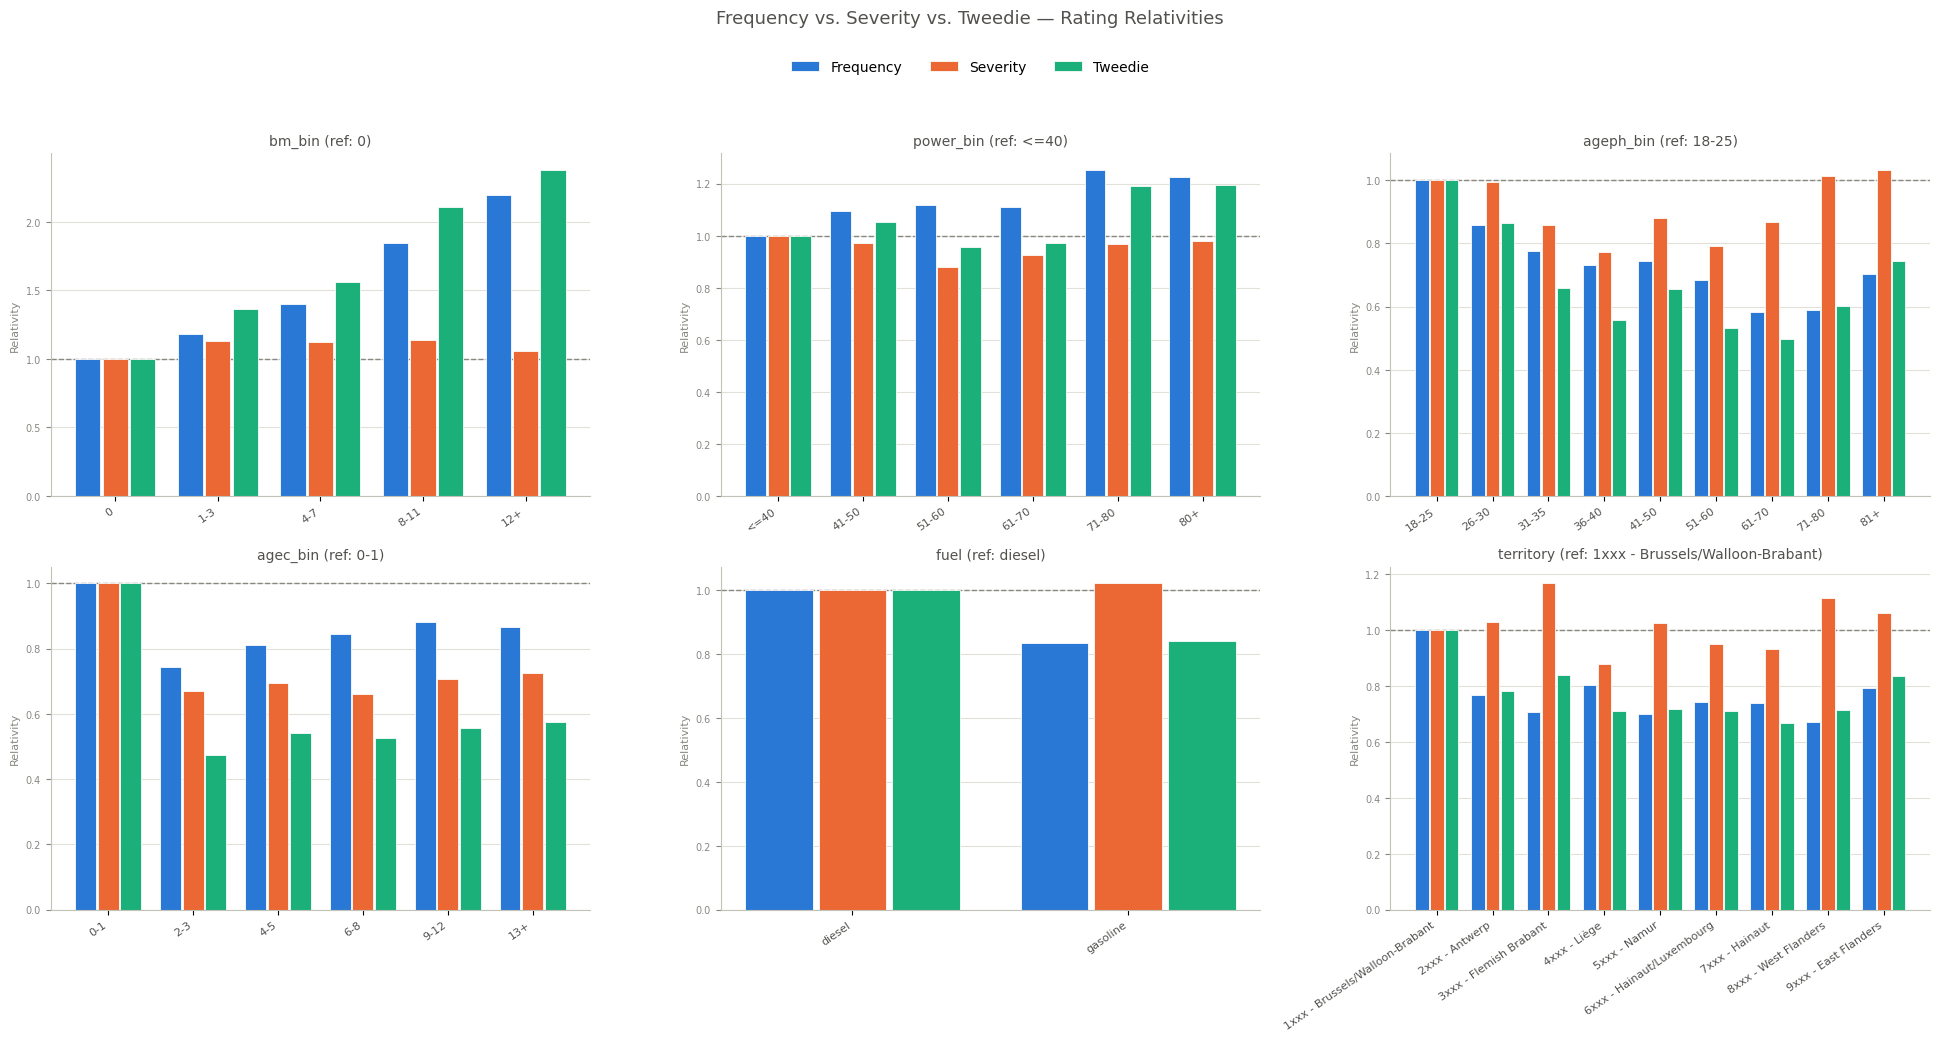

In [41]:
# Categorical slots 1/2/3 (blue/orange/aqua) — validated as a CVD-safe, all-pairs-distinguishable
# trio, which is exactly what three side-by-side series in every panel needs here.
MODEL_SERIES = [
    ('Frequency', freq_rating, '#2a78d6'),
    ('Severity', sev_rating, '#eb6834'),
    ('Tweedie', tw_rating, '#1baf7a'),
]

# Only the six predictors common to all three models (sex excluded everywhere; final_model also dropped use)
shared_vars = freq_categorical_vars

ncols = 3
nrows = -(-len(shared_vars) // ncols)
fig, axs = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.8 * nrows))
axs = np.atleast_1d(axs).flatten()

for ax, var in zip(axs, shared_vars):
    levels = freq_rating.loc[freq_rating['variable'] == var, 'level'].tolist()
    x = np.arange(len(levels))
    n_series = len(MODEL_SERIES)
    width = 0.8 / n_series

    for i, (name, rating_df, color) in enumerate(MODEL_SERIES):
        sub = rating_df[rating_df['variable'] == var].set_index('level').reindex(levels)
        offset = (i - (n_series - 1) / 2) * width
        ax.bar(x + offset, sub['relativity'], width=width * 0.92, color=color,
               edgecolor='#fcfcfb', linewidth=0.6, zorder=2, label=name)

    ax.axhline(1.0, color=COLOR_MUTED, linestyle='--', linewidth=1, zorder=1)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#e1e0d9', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(levels, rotation=35, ha='right', fontsize=8, color=COLOR_INK)
    ax.set_title(f'{var} (ref: {levels[0]})', fontsize=10, color=COLOR_INK)
    ax.set_ylabel('Relativity', fontsize=8, color=COLOR_MUTED)
    ax.tick_params(axis='y', colors=COLOR_MUTED, labelsize=7)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#c3c2b7')

for ax in axs[len(shared_vars):]:
    ax.axis('off')

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.04))
fig.suptitle('Frequency vs. Severity vs. Tweedie — Rating Relativities', fontsize=13, color=COLOR_INK, y=1.08)
plt.tight_layout()
plt.show()

One chart, three bars per category — blue is Frequency, orange is Severity, aqua is Tweedie — so the three models' relativities for the same level sit right next to each other instead of across separate figures. The dashed line marks the reference class (relativity = 1.0) for every variable. Only the six predictors shared by all three models are shown

In [42]:
## Export rating tables, bins, and expense loadings for the standalone Streamlit app

fixed_expense = 60.0
variable_expense_ratio = 0.25
profit_contingency_loading = 0.05

freq_base_rate = np.exp(final_model.params['Intercept'])
sev_base_rate = np.exp(severity_model.params['Intercept'])

print(f"Frequency base rate (exp(Intercept)): {freq_base_rate:.6f}")
print(f"Severity base rate (exp(Intercept)): {sev_base_rate:.2f}")

Frequency base rate (exp(Intercept)): 0.230098
Severity base rate (exp(Intercept)): 1934.04


In [43]:
freq_rating.to_csv('.tmp/freq_rating_table.csv', index=False)
sev_rating.to_csv('.tmp/sev_rating_table.csv', index=False)

model_config = {
    'bins': {
        'bm':    {'edges': bm_bins,    'labels': ['0', '1-3', '4-7', '8-11', '12+']},
        'power': {'edges': power_bins, 'labels': ['<=40', '41-50', '51-60', '61-70', '71-80', '80+']},
        'ageph': {'edges': ageph_bins, 'labels': ['18-25', '26-30', '31-35', '36-40', '41-50', '51-60', '61-70', '71-80', '81+']},
        'agec':  {'edges': agec_bins,  'labels': ['0-1', '2-3', '4-5', '6-8', '9-12', '13+']},
    },
    'territory_labels': territory_labels,
    'base_rates': {'frequency': freq_base_rate, 'severity': sev_base_rate},
    'expense_loadings': {
        'fixed_expense': fixed_expense,
        'variable_expense_ratio': variable_expense_ratio,
        'profit_contingency_loading': profit_contingency_loading,
    },
}
with open('.tmp/model_config.json', 'w') as f:
    json.dump(model_config, f, indent=2)

print("Exported: .tmp/freq_rating_table.csv, .tmp/sev_rating_table.csv, .tmp/model_config.json")

Exported: .tmp/freq_rating_table.csv, .tmp/sev_rating_table.csv, .tmp/model_config.json


## Example of calculating gross premiums

In [44]:
# Example policy:
# Age = 40, Bonus-malus = 5, Horsepower = 60, Vehicle age = 3
# Territory = Brussels, Fuel = Diesel, Use = Private

# Fixed Expenses = 60
# Variable expense ratio = 25%
# Profit & Contingency loading = 5%

example_policy = pd.DataFrame([{
    'ageph': 40,
    'bm': 15,
    'power': 60,
    'agec': 3,
    'territory': '1xxx - Brussels/Walloon-Brabant',
    'fuel': 'diesel',
    'use': 'private',
}])

# Bin the continuous variables with the same bin edges/labels fit on the training data
example_policy = bin_variable(example_policy, 'bm', bins=bm_bins,
                               labels=['0', '1-3', '4-7', '8-11', '12+'])
example_policy = bin_variable(example_policy, 'power', bins=power_bins,
                               labels=['<=40', '41-50', '51-60', '61-70', '71-80', '80+'])
example_policy = bin_variable(example_policy, 'ageph', bins=ageph_bins,
                               labels=['18-25', '26-30', '31-35', '36-40', '41-50', '51-60', '61-70', '71-80', '81+'])
example_policy = bin_variable(example_policy, 'agec', bins=agec_bins,
                               labels=['0-1', '2-3', '4-5', '6-8', '9-12', '13+'])

# Predict frequency (final Poisson model) and severity (Gamma model), then multiply for pure premium
example_policy['pred_frequency'] = final_model.predict(example_policy)
example_policy['pred_severity'] = severity_model.predict(example_policy)
example_policy['pred_pure_premium'] = example_policy['pred_frequency'] * example_policy['pred_severity']

example_policy[['ageph_bin', 'bm_bin', 'power_bin', 'agec_bin', 'territory', 'fuel', 'use',
                'pred_frequency', 'pred_severity', 'pred_pure_premium']]



,ageph_bin,bm_bin,power_bin,agec_bin,territory,fuel,use,pred_frequency,pred_severity,pred_pure_premium
0,36-40,12+,51-60,2-3,1xxx - Brussels/Walloon-Brabant,diesel,private,0.308192,937.568976,288.951467


## Model Diagnostics

The model we use is

$$ \text{Claims} \sim \text{Poisson}(\mu)$$
$$\log{\mu} = \log{\text{Expo}} + x^T\Beta$$

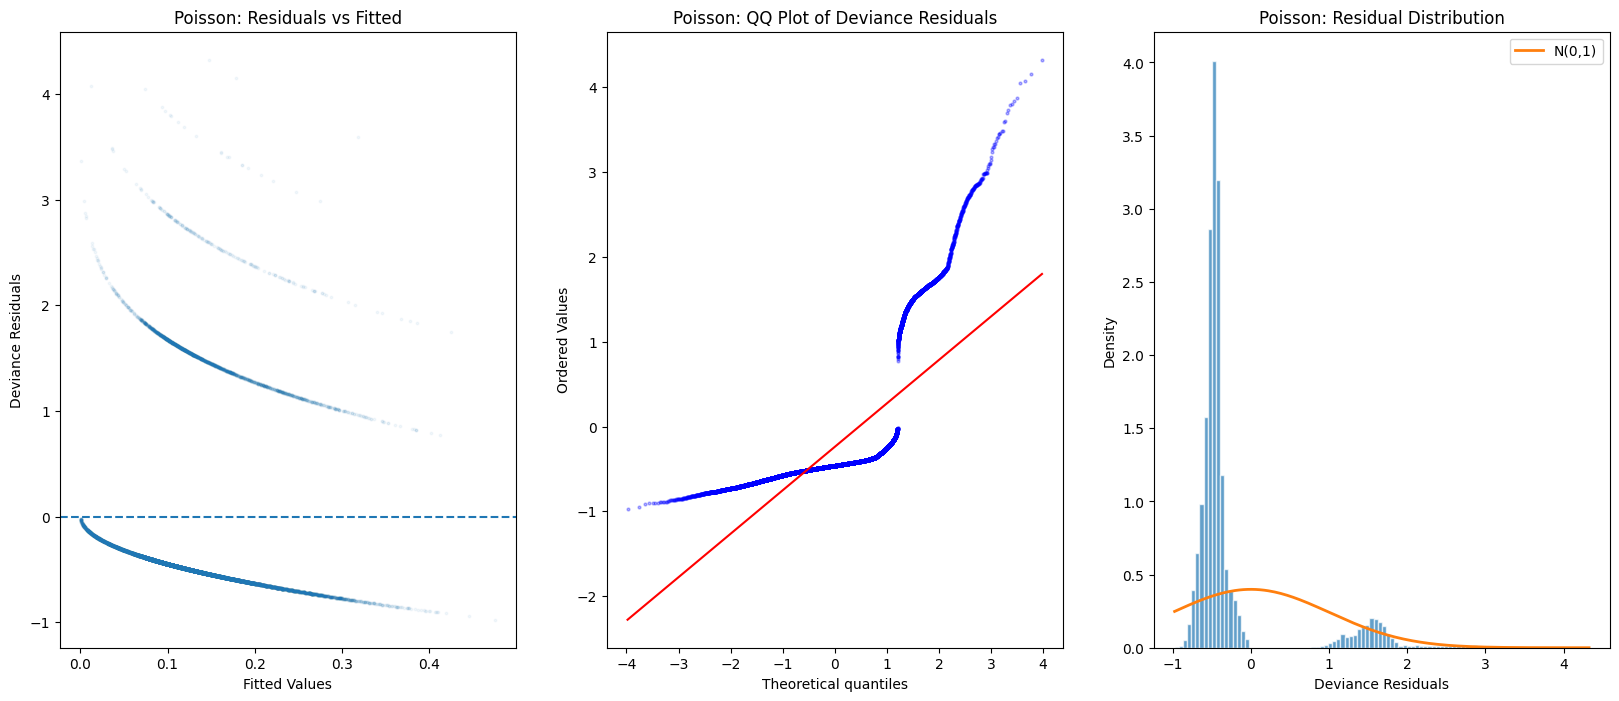

In [45]:
## Poisson Model Diagnostics



fig, axes = plt.subplots(1, 3, figsize=(20, 8))

freq_fittted = final_model.predict(mtpl_train, offset=np.log(mtpl_train['expo'])).values
deviance_residuals = final_model.resid_deviance.values


sample_idx = np.random.choice(len(deviance_residuals), size=min(20000, len(deviance_residuals)), replace=False)

axes[0].scatter(freq_fittted[sample_idx], deviance_residuals[sample_idx],
                alpha=0.05, s=3)
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Deviance Residuals')
axes[0].set_title('Poisson: Residuals vs Fitted')


stats.probplot(deviance_residuals[sample_idx], dist='norm', plot=axes[1])
axes[1].set_title('Poisson: QQ Plot of Deviance Residuals')
axes[1].get_lines()[0].set_markersize(2)
axes[1].get_lines()[0].set_alpha(0.3)


axes[2].hist(deviance_residuals[sample_idx], bins=100, density=True,
             edgecolor='white', alpha=0.7)
x_range = np.linspace(deviance_residuals[sample_idx].min(), deviance_residuals[sample_idx].max(), 200)
axes[2].plot(x_range, stats.norm.pdf(x_range, 0, 1),
             linewidth=2, label='N(0,1)')
axes[2].set_xlabel('Deviance Residuals')
axes[2].set_ylabel('Density')
axes[2].set_title('Poisson: Residual Distribution')
axes[2].legend()


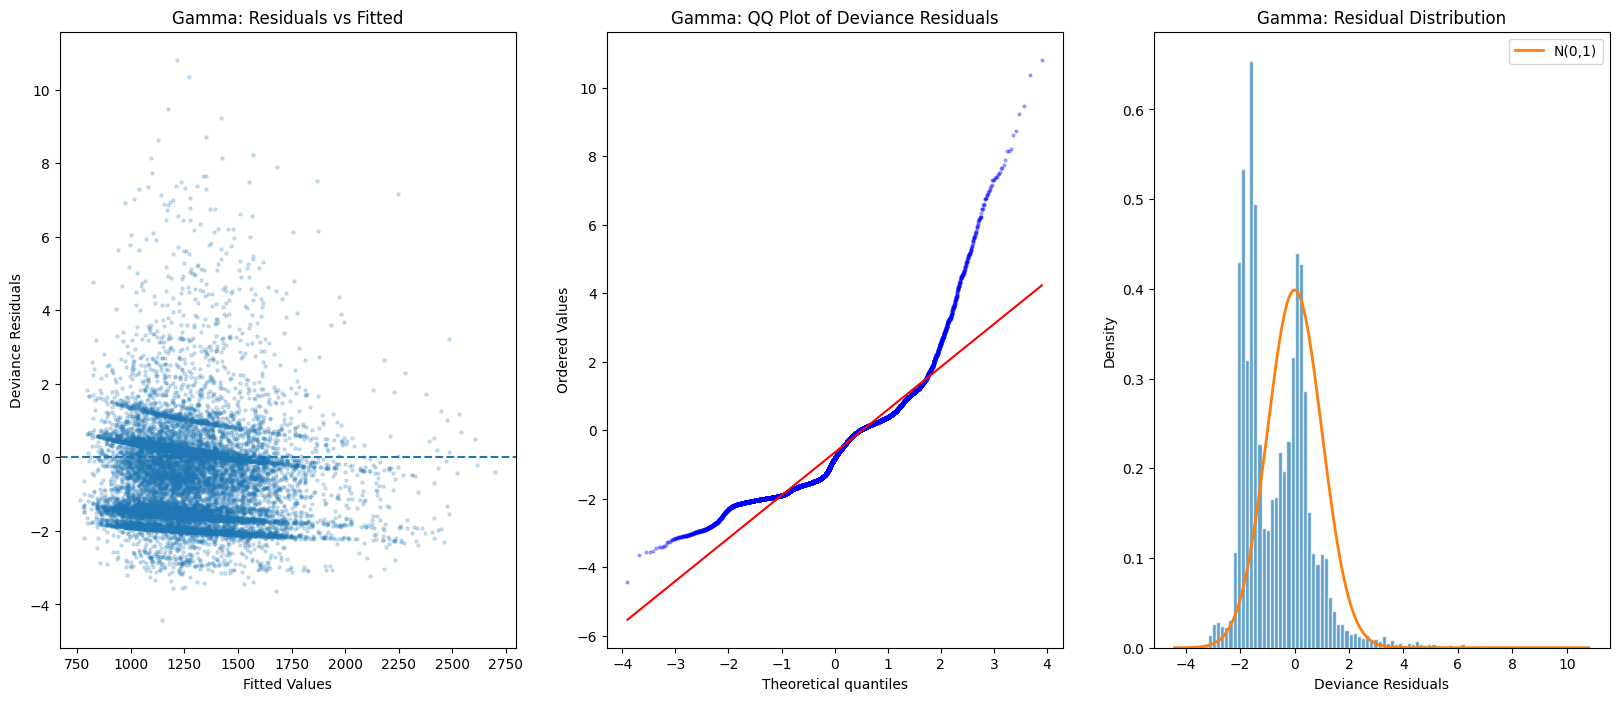

In [46]:
## Gamma Severity Model Diagnostics



fig, axes = plt.subplots(1, 3, figsize=(20, 8))

sev_fitted = severity_model.predict(mtpl_train_sev).values
sev_deviance_residuals = severity_model.resid_deviance


axes[0].scatter(sev_fitted, sev_deviance_residuals, alpha=0.2, s=5)
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Deviance Residuals')
axes[0].set_title('Gamma: Residuals vs Fitted')


stats.probplot(sev_deviance_residuals, dist='norm', plot=axes[1])
axes[1].set_title('Gamma: QQ Plot of Deviance Residuals')
axes[1].get_lines()[0].set_markersize(2)
axes[1].get_lines()[0].set_alpha(0.3)


axes[2].hist(sev_deviance_residuals, bins=100, density=True,
             edgecolor='white', alpha=0.7)
x_range = np.linspace(sev_deviance_residuals.min(), sev_deviance_residuals.max(), 200)
axes[2].plot(x_range, stats.norm.pdf(x_range, 0, 1),
             linewidth=2, label='N(0,1)')
axes[2].set_xlabel('Deviance Residuals')
axes[2].set_ylabel('Density')
axes[2].set_title('Gamma: Residual Distribution')
axes[2].legend()


Observations:

- From the residuals vs fitted values, we don't see any systematic patterns and the model doesn't systematically over predict or under predict the frequency. 
- the QQ plots don't exactly follow a normal distribution, but that is expected with insurance data

### Lorenz Curves & Gini Coefficient

In [102]:
def lorenz_curve(y_true, y_pred, exposure):
    """Compute the ordered Lorenz curve."""
    # Sort by predicted value (ascending)
    order = np.argsort(y_pred)
    y_sorted = y_true[order]
    exp_sorted = exposure[order]

    # Cumulative shares
    cum_exposure = np.cumsum(exp_sorted) / exp_sorted.sum()
    cum_claims = np.cumsum(y_sorted * exp_sorted) / (y_sorted * exp_sorted).sum()

    # Add origin
    cum_exposure = np.concatenate([[0], cum_exposure])
    cum_claims = np.concatenate([[0], cum_claims])

    return cum_exposure, cum_claims


def gini_coefficient(y_true, y_pred, exposure):
    """Compute the Gini coefficient from the ordered Lorenz curve."""
    cum_exp, cum_claims = lorenz_curve(y_true, y_pred, exposure)
    # Area under the Lorenz curve
    auc = np.trapz(cum_claims, cum_exp)
    # Gini = 2 * (0.5 - AUC) = 1 - 2*AUC
    return 1 - 2 * auc

/var/folders/y_/02qd8mcj2_1cxz4yb61lffhr0000gn/T/ipykernel_56325/1514450726.py:23: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = np.trapz(cum_claims, cum_exp)


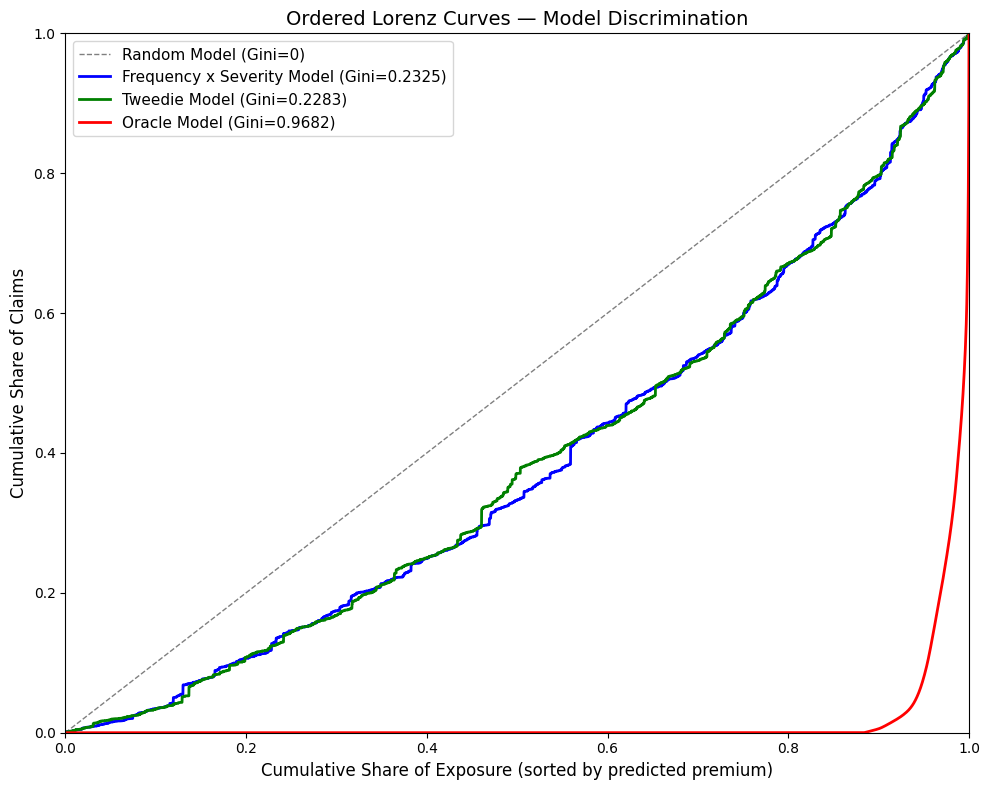

Gini Coefficient (Frequency x Severity): 0.2325
Gini Coefficient (Tweedie): 0.2283


In [109]:
mtpl_test['actual_pure_premium'] = mtpl_test['amount'] / mtpl_test['expo']

y_test = mtpl_test['actual_pure_premium'].values
exp_test = mtpl_test['expo'].values

pred_freqsev = mtpl_test['pred_pure_premium'].values
pred_tweedie = mtpl_test['pred_pure_premium_tweedie'].values

fig, ax = plt.subplots(1, 1, figsize=(10, 8))


ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Model (Gini=0)', alpha=0.5)

cum_exp_fs, cum_claims_fs = lorenz_curve(y_test, pred_freqsev, exp_test)
gini_fs = gini_coefficient(y_test, pred_freqsev, exp_test)
ax.plot(cum_exp_fs, cum_claims_fs, color='blue', linewidth=2, label=f'Frequency x Severity Model (Gini={gini_fs:.4f})')
        
cum_exp_tw, cum_claims_tw = lorenz_curve(y_test, pred_tweedie, exp_test)
gini_tw = gini_coefficient(y_test, pred_tweedie, exp_test)
ax.plot(cum_exp_tw, cum_claims_tw, color='green', linewidth=2, label=f'Tweedie Model (Gini={gini_tw:.4f})')


cum_exp_oracle, cum_claims_oracle = lorenz_curve(y_test, y_test, exp_test)
gini_oracle = gini_coefficient(y_test, y_test, exp_test)
ax.plot(cum_exp_oracle, cum_claims_oracle, color='red', linewidth
=2, label=f'Oracle Model (Gini={gini_oracle:.4f})')
    
ax.set_xlabel('Cumulative Share of Exposure (sorted by predicted premium)', fontsize=12)
ax.set_ylabel('Cumulative Share of Claims', fontsize=12)
ax.set_title('Ordered Lorenz Curves — Model Discrimination', fontsize=14)
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


print(f"Gini Coefficient (Frequency x Severity): {gini_fs:.4f}"
        )
print(f"Gini Coefficient (Tweedie): {gini_tw:.4f}"
        )

## Summary

**What we have done:** we have built an actuarial pipeline that figures out a fair premium for a driver based on things like their age, driving history, and car. We have implemented the following:

|Step   | Model Family  | Purpose  | 
|--------------|--------------|--------------|
| Frequency | Poisson GLM| How often claims occur per year| 
| Severity | Gamma GLM | How much do the claims cost | 


**The data:** 163,212 real car insurance policies from Belgium (one year of history each), including whether they claimed, how much the claim cost, and details about the driver and car.

**Steps we took:**

1. **Cleaned and checked the data** — no missing values. About 11% of policies had at least one claim that year.
2. **Explored what drives risk** — e.g. drivers with a worse bonus-malus (claims history) score claim more often, and both very young and older drivers claim more than drivers in between (a "U-shape").
3. **Grouped continuous numbers into bands** (age, bonus-malus, horsepower, car age) — insurers price in bands (e.g. "ages 25-30") rather than smooth curves, because it's easier to explain and apply.
4. **Built a rough geography factor** from the first digit of the postcode, as a stand-in for region.
5. **Built two prediction models:**
   - *Frequency model* — how often a policy is expected to claim per year.
   - *Severity model* — how much an average claim is expected to cost, given one happens.
   - Dropped factors that didn't meaningfully help (driver sex and vehicle use for frequency). Sex was removed from every model, since pricing by gender is restricted under rules like the EU Gender Directive.
6. **Combined the two** — frequency × severity = pure premium, the expected claims cost per policy before any business costs are added.
7. **Cross-checked** with a different modelling approach (Tweedie GLM fit directly on pure premium) — it gave almost the same results, which is a good sign the models are consistent.
8. **Turned the models into rating tables** — simple lookup tables showing how much more or less each group should pay relative to a baseline (e.g. "this bonus-malus band costs 25% more").
9. **Checked the models are trustworthy** — no obvious bias in the errors, and they correctly separate low-risk from high-risk customers (Lorenz curve / Gini coefficient).
10. **Added business costs** — turned the pure premium into a gross premium (the price a customer actually pays) by adding expenses and a profit margin.
11. **Built a simple app** (Streamlit) so anyone can enter a policy's details and instantly see the predicted frequency, severity, pure premium, and gross premium, without needing to open or run the notebook.

### Key Takeaways: 

- *The Frequency and Severity Relativities behave differently*:  For eg. bonus malus of 12+ is predictive of very high claim count but not claim severity. Thus, a severity and frequency model gives more insight than directly modeling pure premium. 

- **The Frequency X Severity Model and the Tweedie GLM** models perform very similar on predicting total premiums on the test set. 

- **Significant Predictors**: Through variable selection, bonus-malus, driver age, horsepower and region were are statistically signficant predictors of claim frequency. Age of car seems to be a factor direclty related with claims cost. Other factors like region, and horsepower that were important for claims, don't matter here.

-**Tweedie distribution:** It provides a convenient alternative to fitting two separate models, at the cost of losing the decomposition into severity and frequency

